# Ejercicios Propuestos — Modelos de Clasificación
## Material de Refuerzo — Ingeniería del Conocimiento (ISO56B)
### Msc. Jaime Antonio Huaytalla Pariona — UNCP, 2026-II

---

> **Versión resuelta.** Cada ejercicio conserva su enunciado original, seguido de la solución en código y el análisis escrito.

---
## Configuración del entorno

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn import datasets
from sklearn.model_selection import (train_test_split, cross_val_score, cross_val_predict,
                                     cross_validate, StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.inspection import DecisionBoundaryDisplay, permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, make_scorer, roc_curve,
                             roc_auc_score, average_precision_score)

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 100

SEED = 42
np.random.seed(SEED)
print('Entorno listo.')

Entorno listo.


---
## Nivel 1: Básico (Comprensión de conceptos)

### Ejercicio 1.1 — Exploración del dataset Wine
**Dataset:** `sklearn.datasets.load_wine()` (178 muestras, 13 features, 3 clases de vino)

**Tareas:**
1. Cargar el dataset y convertirlo a DataFrame
2. Mostrar las dimensiones, nombres de features y distribución de clases
3. Calcular estadísticas descriptivas por clase
4. Crear un pairplot con las 4 features más relevantes (alcohol, malic_acid, flavanoids, color_intensity)
5. Responder: ¿Las 3 clases se separan visualmente? ¿Qué features parecen más discriminantes?

**Entregable:** Notebook con las visualizaciones y respuestas escritas.

#### Solución

In [2]:
# 1-2. Carga, dimensiones, nombres de features y distribución de clases
wine = datasets.load_wine(as_frame=True)
df_wine = wine.frame.copy()
df_wine['clase'] = df_wine['target'].map(dict(enumerate(wine.target_names)))

print('Dimensiones (muestras, columnas):', df_wine.shape)
print('\nFeatures (%d):' % len(wine.feature_names))
print(', '.join(wine.feature_names))
print('\nDistribución de clases:')
print(df_wine['clase'].value_counts().sort_index())
df_wine.head()

Dimensiones (muestras, columnas): (178, 15)

Features (13):
alcohol, malic_acid, ash, alcalinity_of_ash, magnesium, total_phenols, flavanoids, nonflavanoid_phenols, proanthocyanins, color_intensity, hue, od280/od315_of_diluted_wines, proline

Distribución de clases:
clase
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [3]:
# 3. Estadísticas descriptivas POR CLASE (media y desviación estándar)
print('MEDIA por clase')
display(df_wine.groupby('clase')[wine.feature_names].mean().T.round(2))
print('DESVIACIÓN ESTÁNDAR por clase')
display(df_wine.groupby('clase')[wine.feature_names].std().T.round(2))

MEDIA por clase


clase,class_0,class_1,class_2
alcohol,13.74,12.28,13.15
malic_acid,2.01,1.93,3.33
ash,2.46,2.24,2.44
alcalinity_of_ash,17.04,20.24,21.42
magnesium,106.34,94.55,99.31
total_phenols,2.84,2.26,1.68
flavanoids,2.98,2.08,0.78
nonflavanoid_phenols,0.29,0.36,0.45
proanthocyanins,1.90,1.63,1.15
color_intensity,5.53,3.09,7.40


DESVIACIÓN ESTÁNDAR por clase


clase,class_0,class_1,class_2
alcohol,0.46,0.54,0.53
malic_acid,0.69,1.02,1.09
ash,0.23,0.32,0.18
alcalinity_of_ash,2.55,3.35,2.26
magnesium,10.50,16.75,10.89
total_phenols,0.34,0.55,0.36
flavanoids,0.40,0.71,0.29
nonflavanoid_phenols,0.07,0.12,0.12
proanthocyanins,0.41,0.60,0.41
color_intensity,1.24,0.92,2.31


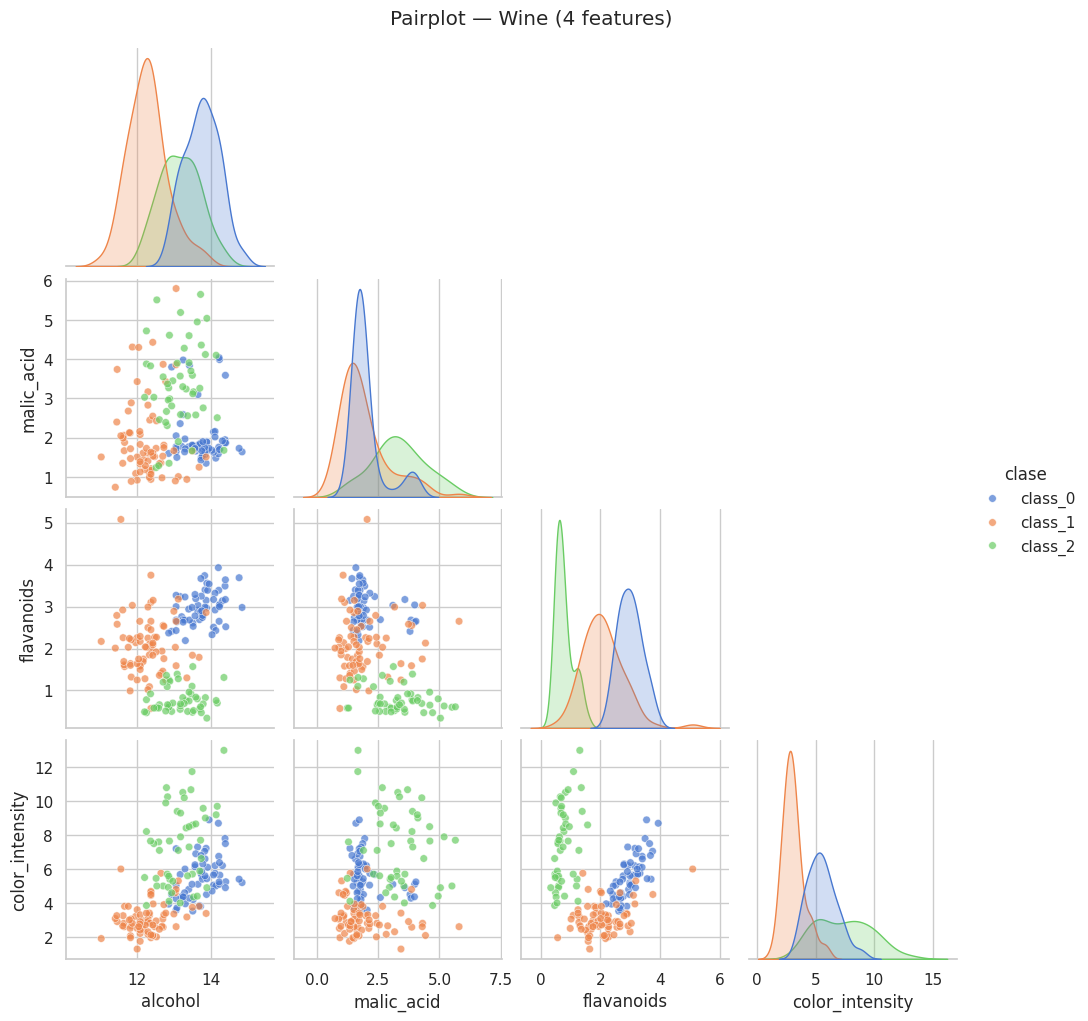

In [4]:
# 4. Pairplot con las 4 features pedidas
cols_pair = ['alcohol', 'malic_acid', 'flavanoids', 'color_intensity']
g = sns.pairplot(df_wine, vars=cols_pair, hue='clase', corner=True,
                 plot_kws=dict(alpha=0.7, s=30), diag_kind='kde')
g.figure.suptitle('Pairplot — Wine (4 features)', y=1.02)
plt.show()

Ranking de poder discriminante (estadístico F de ANOVA, mayor = mejor):
flavanoids                      233.9
proline                         207.9
od280/od315_of_diluted_wines    190.0
alcohol                         135.1
color_intensity                 120.7
hue                             101.3
total_phenols                    93.7
malic_acid                       36.9
alcalinity_of_ash                35.8
proanthocyanins                  30.3
nonflavanoid_phenols             27.6
ash                              13.3
magnesium                        12.4


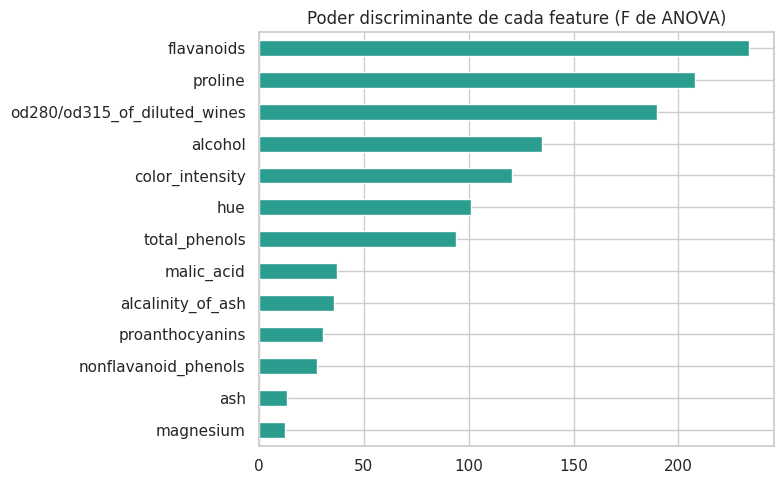

In [5]:
# Apoyo cuantitativo a la pregunta 5: ¿qué features discriminan más entre clases? (F de ANOVA)
F, p = f_classif(wine.data, wine.target)
ranking = pd.Series(F, index=wine.feature_names).sort_values(ascending=False)
print('Ranking de poder discriminante (estadístico F de ANOVA, mayor = mejor):')
print(ranking.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
ranking.sort_values().plot.barh(ax=ax, color='#2a9d8f')
ax.set_title('Poder discriminante de cada feature (F de ANOVA)')
plt.tight_layout(); plt.show()

#### Respuesta
**¿Las 3 clases se separan visualmente?** En buena medida sí. Ninguna feature separa las tres clases por sí sola, pero combinadas sí: por ejemplo, `flavanoids` distingue la clase 2 (media ≈ 0.78) de la clase 0 (≈ 2.98), y `color_intensity` distingue la clase 1 (≈ 3.09) de las otras dos (≈ 5.5 y 7.4). Con `alcohol` se aprecia que la clase 1 tiene menos grado (≈ 12.3 vs ≈ 13.7 de la clase 0). `malic_acid` es la más débil: solo la clase 2 tiene una media claramente mayor (≈ 3.3) y hay mucho solapamiento (desviaciones ≈ 1).

**¿Qué features parecen más discriminantes?** Considerando las 13 variables (estadístico F de ANOVA), las más discriminantes son `flavanoids` (F ≈ 234), `proline` (≈ 208) y `od280/od315_of_diluted_wines` (≈ 190). De las 4 que pedía el ejercicio, `flavanoids` y `alcohol`/`color_intensity` son las que más ayudan; `malic_acid` es la menos útil (F ≈ 37).

### Ejercicio 1.2 — Train/Test Split y su efecto
**Dataset:** `sklearn.datasets.load_iris()`

**Tareas:**
1. Entrenar una Regresión Logística con 3 splits diferentes: test_size=0.1, 0.3, 0.5
2. Reportar accuracy en train y test para cada split
3. Repetir el experimento con random_state=0, 7, 42, 99 (fijando test_size=0.2) y reportar cómo varía la accuracy
4. Responder: ¿Por qué cambian los resultados con distinto random_state? ¿Qué solución propones?

**Entregable:** Tabla comparativa y respuesta razonada.

#### Solución

In [6]:
iris = datasets.load_iris()
X_iris, y_iris = iris.data, iris.target

# 1-2. Tres tamaños de test distintos (random_state fijo = 42)
filas = []
for ts in [0.1, 0.3, 0.5]:
    Xtr, Xte, ytr, yte = train_test_split(X_iris, y_iris, test_size=ts, random_state=42)
    m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    filas.append({'test_size': ts, 'n_train': len(Xtr), 'n_test': len(Xte),
                  'acc_train': m.score(Xtr, ytr), 'acc_test': m.score(Xte, yte)})
tabla_ts = pd.DataFrame(filas)
display(tabla_ts.round(4))

,test_size,n_train,n_test,acc_train,acc_test
0,0.1,135,15,0.9778,1.0
1,0.3,105,45,0.9619,1.0
2,0.5,75,75,0.9200,1.0


In [7]:
# 3. Variación con random_state (test_size = 0.2 fijo)
filas = []
for rs in [0, 7, 42, 99]:
    Xtr, Xte, ytr, yte = train_test_split(X_iris, y_iris, test_size=0.2, random_state=rs)
    m = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    filas.append({'random_state': rs, 'acc_train': m.score(Xtr, ytr), 'acc_test': m.score(Xte, yte)})
tabla_rs = pd.DataFrame(filas)
display(tabla_rs.round(4))
print('Desviación estándar de acc_test entre semillas: %.4f' % tabla_rs['acc_test'].std())
print('Rango (máx - mín): %.4f' % (tabla_rs['acc_test'].max() - tabla_rs['acc_test'].min()))

,random_state,acc_train,acc_test
0,0,0.9667,1.0000
1,7,0.9917,0.8667
2,42,0.9750,1.0000
3,99,0.9833,0.9333


Desviación estándar de acc_test entre semillas: 0.0638
Rango (máx - mín): 0.1333


In [8]:
# 4. Solución propuesta: validación cruzada estratificada repetida (promedia sobre muchas particiones)
from sklearn.model_selection import RepeatedStratifiedKFold
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scores = cross_val_score(LogisticRegression(max_iter=1000), X_iris, y_iris, cv=rcv)
print('CV 5-fold x 10 repeticiones (50 evaluaciones)')
print('Accuracy media: %.4f   desviación estándar: %.4f' % (scores.mean(), scores.std()))
print('Rango observado: %.3f - %.3f' % (scores.min(), scores.max()))

CV 5-fold x 10 repeticiones (50 evaluaciones)
Accuracy media: 0.9647   desviación estándar: 0.0301
Rango observado: 0.900 - 1.000


#### Respuesta
**¿Por qué cambian los resultados con distinto `random_state`?** Porque cada semilla produce una partición distinta: la accuracy en test varió entre 0.867 y 1.000 (rango 0.133, desviación 0.064) solo por cambiar la semilla. Con `test_size=0.2` el test tiene 30 muestras, así que cada error cuesta ≈ 3.3 puntos, y según la semilla caen en test más o menos de los casos difíciles (la frontera versicolor/virginica). Lo mismo ocurre con el tamaño: que el test dé 1.000 en las tres divisiones no demuestra que el modelo sea perfecto, solo que con 15–75 muestras la estimación es muy ruidosa. Además, los accuracy de *train* distintos (0.978 → 0.920) vienen de entrenar con conjuntos distintos y más pequeños.

**Solución propuesta:** no depender de una sola partición. Con validación cruzada estratificada repetida (5-fold × 10 repeticiones = 50 evaluaciones) la accuracy es **0.965 ± 0.030**, una estimación mucho más estable y honesta; y como mínimo usar `stratify=y` en `train_test_split`.

### Ejercicio 1.3 — Efecto de la estandarización
**Dataset:** `sklearn.datasets.load_breast_cancer()`

**Tareas:**
1. Entrenar un KNN (K=5) **sin** estandarizar y reportar accuracy
2. Entrenar el mismo KNN **con** StandardScaler y reportar accuracy
3. Entrenar un Árbol de Decisión con y sin estandarización
4. Crear una tabla comparativa con los 4 resultados
5. Responder: ¿Cuál modelo es afectado por la estandarización y cuál no? ¿Por qué?

**Entregable:** Tabla y explicación.

#### Solución

In [9]:
bc = datasets.load_breast_cancer()
Xb, yb = bc.data, bc.target
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=42, stratify=yb)

modelos_13 = {
    'KNN (K=5) sin estandarizar': KNeighborsClassifier(n_neighbors=5),
    'KNN (K=5) estandarizado': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Árbol sin estandarizar': DecisionTreeClassifier(random_state=42),
    'Árbol estandarizado': make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=42)),
}
filas = []
for nombre, mod in modelos_13.items():
    mod.fit(Xb_tr, yb_tr)
    cv_acc = cross_val_score(mod, Xb_tr, yb_tr, cv=StratifiedKFold(5, shuffle=True, random_state=42)).mean()
    filas.append({'Modelo': nombre, 'Accuracy test': accuracy_score(yb_te, mod.predict(Xb_te)),
                  'Accuracy CV (train)': cv_acc})
tabla_13 = pd.DataFrame(filas)
display(tabla_13.round(4))

,Modelo,Accuracy test,Accuracy CV (train)
0,KNN (K=5) sin estandarizar,0.9123,0.9407
1,KNN (K=5) estandarizado,0.9561,0.9626
2,Árbol sin estandarizar,0.9123,0.9165
3,Árbol estandarizado,0.9123,0.9165


In [10]:
# Evidencia de POR QUÉ: escalas de las features (la distancia euclídea la dominan las de mayor escala)
escalas = pd.DataFrame(Xb, columns=bc.feature_names).std().sort_values(ascending=False)
print('Features con mayor y menor desviación estándar:')
print(pd.concat([escalas.head(3), escalas.tail(3)]).round(4).to_string())

Features con mayor y menor desviación estándar:
worst area                 569.3570
mean area                  351.9141
area error                  45.4910
concave points error         0.0062
smoothness error             0.0030
fractal dimension error      0.0026


#### Respuesta
| Modelo | Accuracy test |
|---|---|
| KNN sin estandarizar | 0.912 |
| KNN estandarizado | **0.956** |
| Árbol sin estandarizar | 0.912 |
| Árbol estandarizado | 0.912 |

**¿Cuál modelo es afectado y cuál no?** **KNN sí** (mejora de 0.912 a 0.956 en test y de 0.941 a 0.963 en CV); **el árbol no** (resultados idénticos).

**¿Por qué?** KNN se basa en distancias euclídeas: en Breast Cancer unas features tienen desviación estándar enorme (`worst area` ≈ 569, `mean area` ≈ 352) y otras minúscula (`fractal dimension error` ≈ 0.003), de modo que sin estandarizar la distancia la dominan prácticamente solo las variables de área y las demás no cuentan. El árbol, en cambio, decide con umbrales sobre **una feature a la vez**, y un cambio de escala (transformación monótona) no altera el orden de los datos ni, por tanto, los cortes posibles: el árbol resultante es el mismo.

---
## Nivel 2: Intermedio (Aplicación de algoritmos)

### Ejercicio 2.1 — Clasificación de dígitos escritos a mano
**Dataset:** `sklearn.datasets.load_digits()` (1797 imágenes de 8×8 píxeles, 10 clases)

**Tareas:**
1. Cargar el dataset y visualizar 20 imágenes aleatorias con sus etiquetas
2. Dividir en train/test (80/20, estratificado)
3. Entrenar 3 modelos: Regresión Logística, SVM (RBF), KNN (K=5)
4. Para cada modelo: mostrar accuracy, classification_report y matriz de confusión
5. Identificar: ¿Qué dígitos se confunden más entre sí? ¿Tiene sentido visualmente?
6. Crear un gráfico de barras comparando accuracy por modelo

**Entregable:** Notebook completo con análisis.

#### Solución

Imágenes: 1797 | píxeles por imagen: 64 | clases: 10


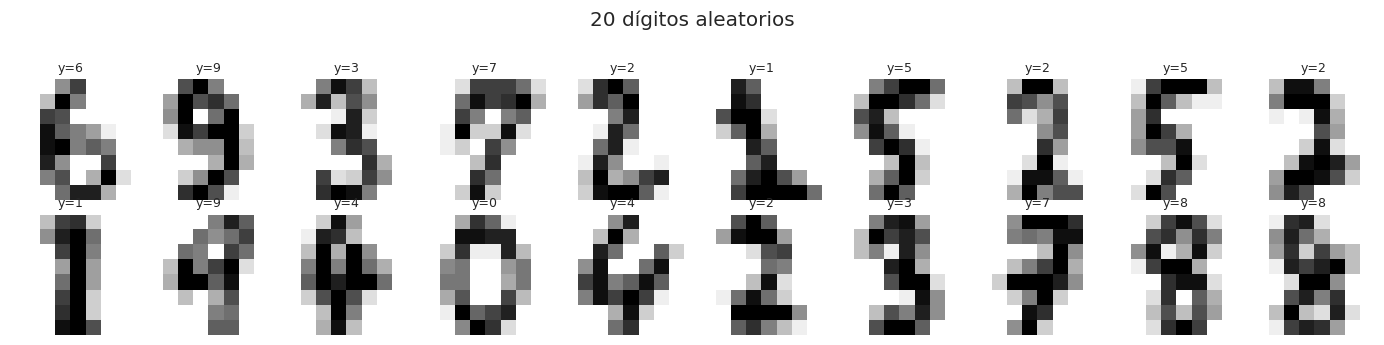

In [11]:
digits = datasets.load_digits()
Xd, yd = digits.data, digits.target
print('Imágenes:', Xd.shape[0], '| píxeles por imagen:', Xd.shape[1], '| clases:', len(np.unique(yd)))

# 1. 20 imágenes aleatorias con su etiqueta
rng = np.random.RandomState(42)
idx = rng.choice(len(Xd), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(digits.images[i], cmap='gray_r')
    ax.set_title('y=%d' % yd[i], fontsize=9)
    ax.axis('off')
plt.suptitle('20 dígitos aleatorios', y=1.02)
plt.tight_layout(); plt.show()

In [12]:
# 2-4. Split 80/20 estratificado, 3 modelos, métricas y matrices de confusión
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, yd, test_size=0.2, random_state=42, stratify=yd)

modelos_d = {
    'Regresión Logística': LogisticRegression(max_iter=5000),
    'SVM (RBF)': SVC(kernel='rbf'),
    'KNN (K=5)': KNeighborsClassifier(n_neighbors=5),
}
pred_d, acc_d = {}, {}
for nombre, mod in modelos_d.items():
    mod.fit(Xd_tr, yd_tr)
    pred_d[nombre] = mod.predict(Xd_te)
    acc_d[nombre] = accuracy_score(yd_te, pred_d[nombre])
    print('=' * 60)
    print('%s — accuracy test: %.4f' % (nombre, acc_d[nombre]))
    print(classification_report(yd_te, pred_d[nombre], digits=3))

Regresión Logística — accuracy test: 0.9583
              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.889     0.889     0.889        36
           2      0.972     1.000     0.986        35
           3      0.949     1.000     0.974        37
           4      0.947     1.000     0.973        36
           5      0.973     0.973     0.973        37
           6      1.000     0.972     0.986        36
           7      1.000     0.972     0.986        36
           8      0.857     0.857     0.857        35
           9      1.000     0.944     0.971        36

    accuracy                          0.958       360
   macro avg      0.959     0.958     0.958       360
weighted avg      0.959     0.958     0.958       360

SVM (RBF) — accuracy test: 0.9917
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        36
           1      0.947     1.000     0.973        36


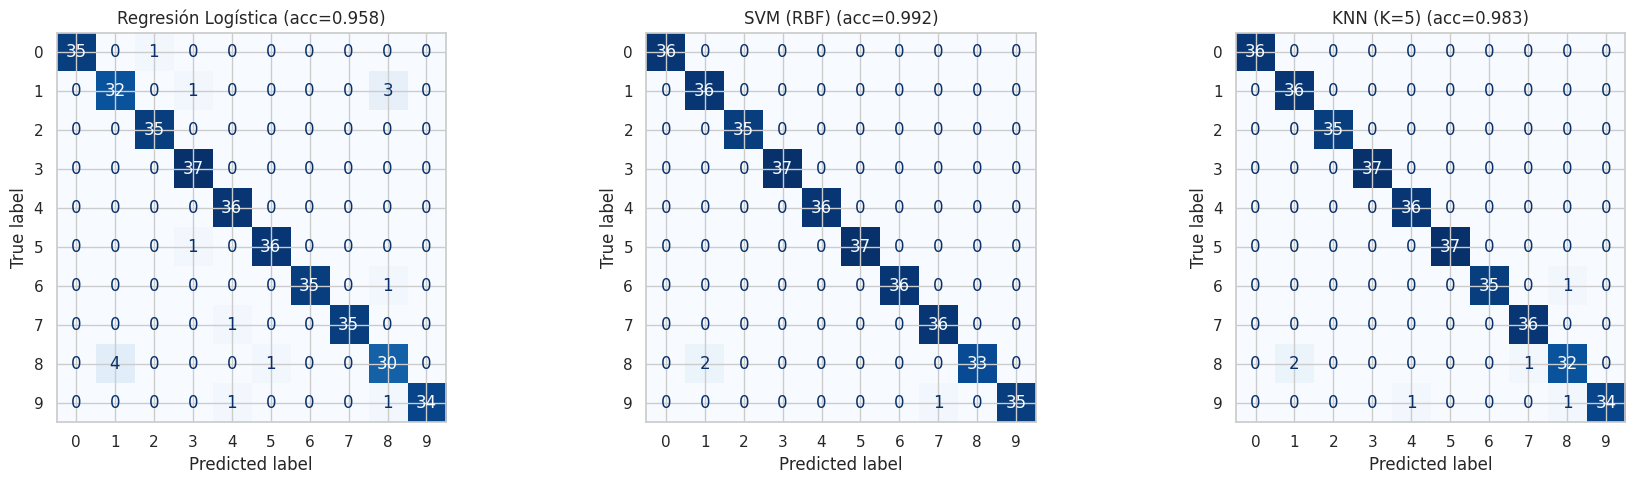

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nombre, p) in zip(axes, pred_d.items()):
    ConfusionMatrixDisplay.from_predictions(yd_te, p, cmap='Blues', ax=ax, colorbar=False)
    ax.set_title('%s (acc=%.3f)' % (nombre, acc_d[nombre]))
plt.tight_layout(); plt.show()

Modelo analizado (menor accuracy): Regresión Logística
Pares más confundidos (verdadero<->predicho):
   1 <-> 8 : 7 errores
   0 <-> 2 : 1 errores
   1 <-> 3 : 1 errores
   3 <-> 5 : 1 errores
   4 <-> 7 : 1 errores


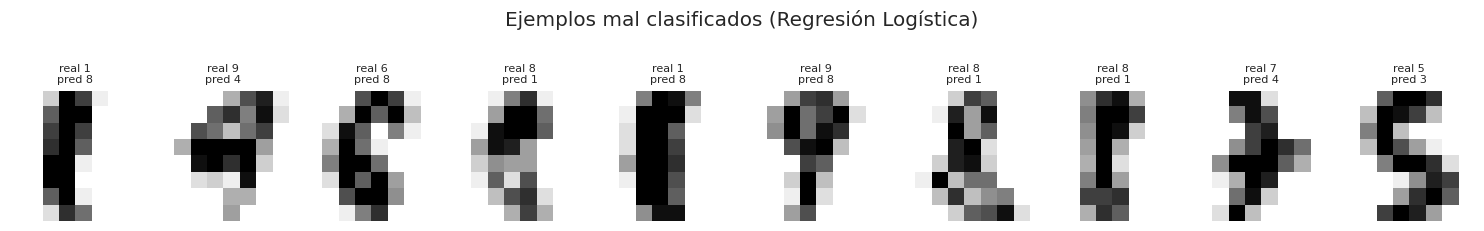

In [14]:
# 5. Pares de dígitos más confundidos (suma de errores en ambos sentidos) con el modelo de peor desempeño
peor = min(acc_d, key=acc_d.get)
cm = confusion_matrix(yd_te, pred_d[peor])
errores = []
for i in range(10):
    for j in range(i + 1, 10):
        errores.append(((i, j), cm[i, j] + cm[j, i]))
errores.sort(key=lambda t: -t[1])
print('Modelo analizado (menor accuracy): %s' % peor)
print('Pares más confundidos (verdadero<->predicho):')
for (i, j), n in errores[:5]:
    print('   %d <-> %d : %d errores' % (i, j, n))

# Ejemplos de imágenes mal clasificadas
mal = np.where(pred_d[peor] != yd_te)[0][:10]
fig, axes = plt.subplots(1, len(mal), figsize=(1.5 * len(mal), 2.2))
for ax, k in zip(np.atleast_1d(axes), mal):
    ax.imshow(Xd_te[k].reshape(8, 8), cmap='gray_r')
    ax.set_title('real %d\npred %d' % (yd_te[k], pred_d[peor][k]), fontsize=8)
    ax.axis('off')
plt.suptitle('Ejemplos mal clasificados (%s)' % peor, y=1.08)
plt.tight_layout(); plt.show()

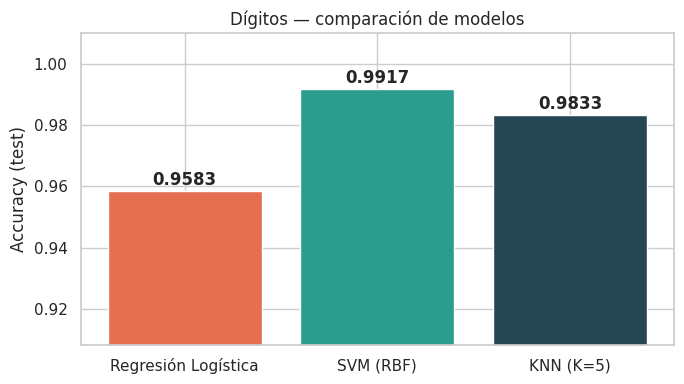

In [15]:
# 6. Gráfico de barras comparando accuracy por modelo
fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(list(acc_d.keys()), list(acc_d.values()), color=['#e76f51', '#2a9d8f', '#264653'])
for b, v in zip(barras, acc_d.values()):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.002, '%.4f' % v, ha='center', fontweight='bold')
ax.set_ylim(min(acc_d.values()) - 0.05, 1.01)
ax.set_ylabel('Accuracy (test)'); ax.set_title('Dígitos — comparación de modelos')
plt.tight_layout(); plt.show()

#### Respuesta
Accuracy en test: **SVM (RBF) 0.992**, **KNN 0.983**, **Regresión Logística 0.958**. El SVM comete apenas 3 errores en 360 imágenes.

**¿Qué dígitos se confunden más?** En el modelo más débil (Regresión Logística) el par más confundido es **1 ↔ 8** (7 errores; los demás pares suman 1 error cada uno), y también son los dígitos con menor F1 (1: 0.889, 8: 0.857). Tiene sentido visual: a solo 8×8 píxeles, un 8 pierde la nitidez de sus dos lazos y un 1 con trazo grueso o inclinado ocupa una zona parecida, así que un modelo lineal que pondera píxeles de forma independiente los confunde. Los modelos no lineales (SVM-RBF, KNN) capturan mejor la forma global y casi no se equivocan.

### Ejercicio 2.2 — Búsqueda del K óptimo en KNN
**Dataset:** `sklearn.datasets.load_wine()`

**Tareas:**
1. Estandarizar los datos
2. Probar KNN con K de 1 a 30
3. Para cada K, calcular accuracy en train y test
4. Graficar ambas curvas en un solo gráfico (X: K, Y: accuracy)
5. Identificar la zona de overfitting (K bajo) y underfitting (K alto)
6. Reportar el K óptimo y entrenar el modelo final con ese K
7. Mostrar classification_report del modelo final

**Entregable:** Gráfico anotado y modelo final evaluado.

#### Solución

In [16]:
# 1. Split primero y estandarización DESPUÉS (el scaler se ajusta solo con train: sin data leakage)
Xw, yw = wine.data, wine.target
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.3, random_state=42, stratify=yw)
sc = StandardScaler().fit(Xw_tr)
Xw_tr_s, Xw_te_s = sc.transform(Xw_tr), sc.transform(Xw_te)

# 2-3. KNN con K de 1 a 30: accuracy en train y en test
ks = range(1, 31)
acc_tr_k = [KNeighborsClassifier(n_neighbors=k).fit(Xw_tr_s, yw_tr).score(Xw_tr_s, yw_tr) for k in ks]
acc_te_k = [KNeighborsClassifier(n_neighbors=k).fit(Xw_tr_s, yw_tr).score(Xw_te_s, yw_te) for k in ks]

# K óptimo elegido por validación cruzada SOBRE TRAIN (no sobre test, para no "espiar" el test)
cv_k = [cross_val_score(KNeighborsClassifier(n_neighbors=k), Xw_tr_s, yw_tr,
                        cv=StratifiedKFold(5, shuffle=True, random_state=42)).mean() for k in ks]
k_opt = list(ks)[int(np.argmax(cv_k))]          # ante empate, el K más pequeño entre los mejores
print('K óptimo (máx. accuracy CV en train): K = %d  (CV acc = %.4f)' % (k_opt, max(cv_k)))

K óptimo (máx. accuracy CV en train): K = 14  (CV acc = 0.9760)


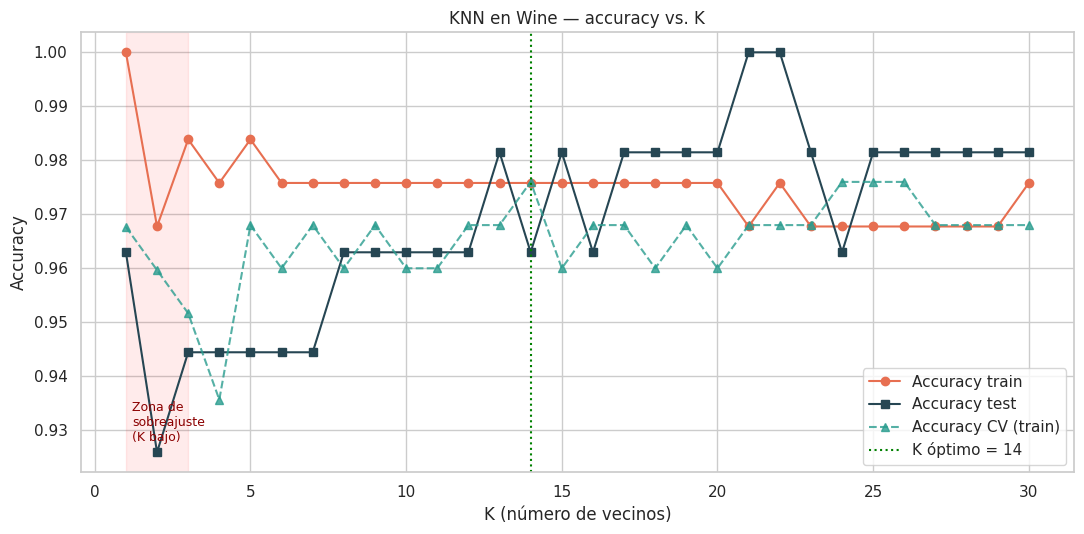

In [17]:
# 4-5. Gráfico anotado: sobreajuste (K bajo) y subajuste (K alto)
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(ks, acc_tr_k, 'o-', label='Accuracy train', color='#e76f51')
ax.plot(ks, acc_te_k, 's-', label='Accuracy test', color='#264653')
ax.plot(ks, cv_k, '^--', label='Accuracy CV (train)', color='#2a9d8f', alpha=0.8)
ax.axvline(k_opt, color='green', linestyle=':', label='K óptimo = %d' % k_opt)
ax.axvspan(1, 3, color='red', alpha=0.08)
ax.text(1.2, min(acc_te_k) + 0.002, 'Zona de\nsobreajuste\n(K bajo)', fontsize=9, color='darkred')
ax.set_xlabel('K (número de vecinos)'); ax.set_ylabel('Accuracy')
ax.set_title('KNN en Wine — accuracy vs. K')
ax.legend(loc='lower right'); plt.tight_layout(); plt.show()

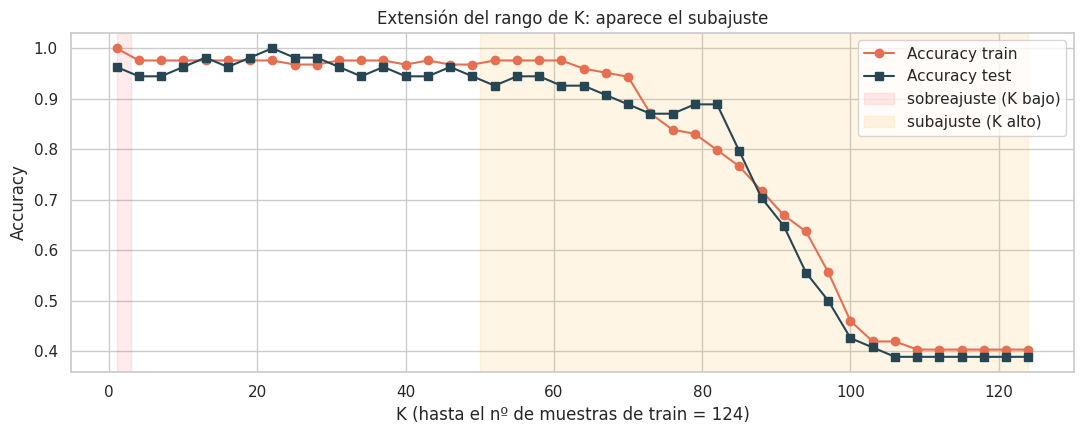

KNN final (K=14) — accuracy test: 0.9630

              precision    recall  f1-score   support

     class_0      0.947     1.000     0.973        18
     class_1      1.000     0.905     0.950        21
     class_2      0.938     1.000     0.968        15

    accuracy                          0.963        54
   macro avg      0.962     0.968     0.964        54
weighted avg      0.965     0.963     0.963        54



In [18]:
# Extensión del rango (K hasta el tamaño del train) para VER la zona de subajuste, que en K<=30 aún no aparece en Wine
ks_ext = list(range(1, 125, 3))
tr_ext = [KNeighborsClassifier(n_neighbors=k).fit(Xw_tr_s, yw_tr).score(Xw_tr_s, yw_tr) for k in ks_ext]
te_ext = [KNeighborsClassifier(n_neighbors=k).fit(Xw_tr_s, yw_tr).score(Xw_te_s, yw_te) for k in ks_ext]
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(ks_ext, tr_ext, 'o-', label='Accuracy train', color='#e76f51')
ax.plot(ks_ext, te_ext, 's-', label='Accuracy test', color='#264653')
ax.axvspan(1, 3, color='red', alpha=0.08, label='sobreajuste (K bajo)')
ax.axvspan(50, 124, color='orange', alpha=0.10, label='subajuste (K alto)')
ax.set_xlabel('K (hasta el nº de muestras de train = %d)' % len(yw_tr)); ax.set_ylabel('Accuracy')
ax.set_title('Extensión del rango de K: aparece el subajuste'); ax.legend(); plt.tight_layout(); plt.show()

# 6-7. Modelo final con el K óptimo y su classification_report en test
knn_final = KNeighborsClassifier(n_neighbors=k_opt).fit(Xw_tr_s, yw_tr)
y_pred_final = knn_final.predict(Xw_te_s)
print('KNN final (K=%d) — accuracy test: %.4f\n' % (k_opt, accuracy_score(yw_te, y_pred_final)))
print(classification_report(yw_te, y_pred_final, target_names=wine.target_names, digits=3))

#### Respuesta
- **K óptimo = 14**, elegido por validación cruzada *dentro del train* (accuracy CV = 0.976), no mirando el test; con ese K el modelo final obtiene 0.963 de accuracy en test.
- **Sobreajuste (K bajo):** con K = 1 el accuracy en train es 1.000 (cada punto es su propio vecino), pero la curva de test es irregular y cae a 0.926 con K = 2 y a ≈ 0.944 con K = 3–7, por debajo del 0.96–0.98 que se logra con K ≥ 8. El modelo memoriza el ruido.
- **Subajuste (K alto):** en el rango pedido (K ≤ 30) todavía no se nota —con 124 muestras de train y ≈ 40 por clase, K = 30 sigue siendo razonable—, por eso añadí el gráfico extendido: desde K ≈ 50 el accuracy de test cae (0.926 en K = 50, 0.889 en K = 70, 0.648 en K = 90) y cuando K se acerca al tamaño del train el modelo solo predice la clase mayoritaria (≈ 0.39).
- La curva es muy plana entre K = 8 y K = 30 (≈ 0.96–0.98): en un dataset de 178 muestras las diferencias de 1–2 muestras de test no son significativas, por eso conviene elegir K con validación cruzada.

### Ejercicio 2.3 — Comparación de kernels en SVM
**Dataset:** Crear datos sintéticos con `make_moons` y `make_circles`

**Tareas:**
1. Generar 500 muestras con `make_moons(noise=0.3)` y 500 con `make_circles(noise=0.2, factor=0.5)`
2. Para cada dataset, entrenar SVM con kernel lineal, RBF y polinomial (grado 3)
3. Visualizar las fronteras de decisión de cada kernel (gráfico 2D con regiones coloreadas)
4. Reportar accuracy para cada combinación (dataset × kernel)
5. Responder: ¿Por qué el kernel lineal falla en `make_moons`? ¿Qué kernel funciona mejor para cada forma de datos?

**Pista para visualizar fronteras:**
```python
from sklearn.inspection import DecisionBoundaryDisplay
```

**Entregable:** 6 gráficos (2 datasets × 3 kernels) y tabla de accuracies.

#### Solución

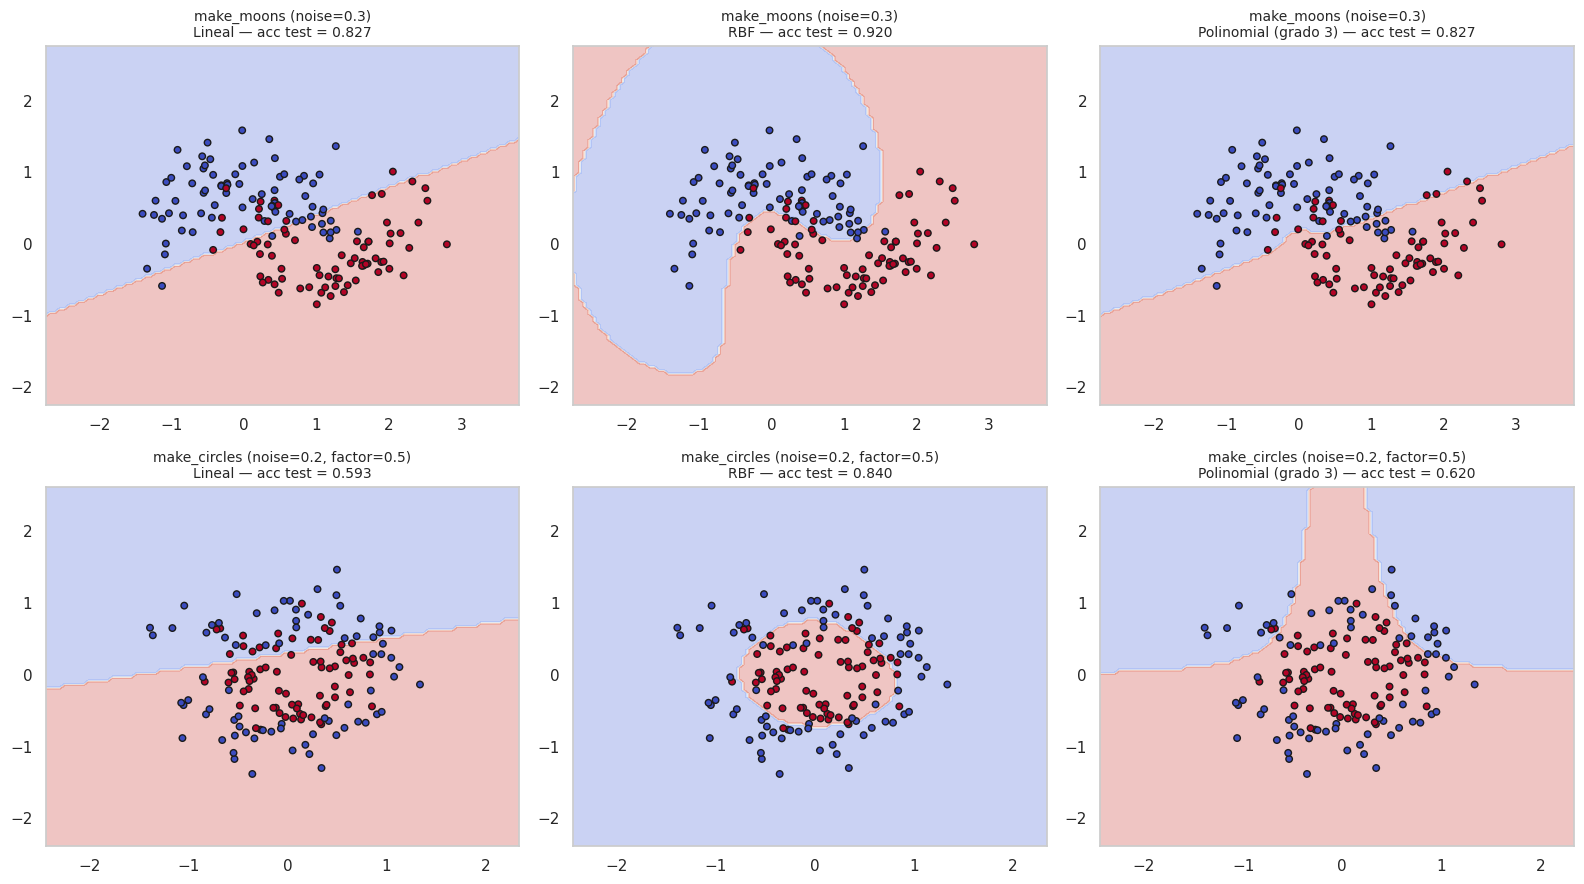

In [19]:
from sklearn.datasets import make_moons, make_circles

datos_23 = {
    'make_moons (noise=0.3)': make_moons(n_samples=500, noise=0.3, random_state=42),
    'make_circles (noise=0.2, factor=0.5)': make_circles(n_samples=500, noise=0.2, factor=0.5, random_state=42),
}
kernels = {'Lineal': SVC(kernel='linear'), 'RBF': SVC(kernel='rbf'), 'Polinomial (grado 3)': SVC(kernel='poly', degree=3)}

resultados_23 = {}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for fila, (nom_d, (X23, y23)) in enumerate(datos_23.items()):
    Xtr, Xte, ytr, yte = train_test_split(X23, y23, test_size=0.3, random_state=42, stratify=y23)
    for col, (nom_k, svm) in enumerate(kernels.items()):
        svm = SVC(**svm.get_params()).fit(Xtr, ytr)
        acc = svm.score(Xte, yte)
        resultados_23[(nom_d, nom_k)] = acc
        ax = axes[fila, col]
        DecisionBoundaryDisplay.from_estimator(svm, X23, response_method='predict',
                                               cmap=plt.cm.coolwarm, alpha=0.3, ax=ax)
        ax.scatter(Xte[:, 0], Xte[:, 1], c=yte, cmap=plt.cm.coolwarm, edgecolor='k', s=22)
        ax.grid(False)
        ax.set_title('%s\n%s — acc test = %.3f' % (nom_d, nom_k, acc), fontsize=10)
plt.tight_layout(); plt.show()

In [20]:
tabla_23 = pd.Series(resultados_23).unstack().round(4)
print('Accuracy en test (filas = dataset, columnas = kernel):')
display(tabla_23)

Accuracy en test (filas = dataset, columnas = kernel):


,Lineal,Polinomial (grado 3),RBF
"make_circles (noise=0.2, factor=0.5)",0.5933,0.6200,0.84
make_moons (noise=0.3),0.8267,0.8267,0.92


#### Respuesta
| Dataset | Lineal | RBF | Polinomial (g=3) |
|---|---|---|---|
| make_moons | 0.827 | **0.920** | 0.827 |
| make_circles | 0.593 | **0.840** | 0.620 |

**¿Por qué el kernel lineal falla en `make_moons`?** Porque las dos clases son medias lunas entrelazadas: ninguna recta (hiperplano) puede dejar cada luna de un lado; lo mejor que logra es una diagonal que mezcla puntos de ambas (≈ 83 %). En `make_circles` es todavía peor (≈ 59 %, casi azar) porque una clase rodea a la otra y no existe ningún separador lineal.

**¿Qué kernel funciona mejor?** **RBF en ambos**: construye fronteras locales y curvas (la frontera de `make_circles` es una región cerrada alrededor del círculo interior). El polinomial de grado 3 apenas mejora al lineal: sus fronteras son curvas globales poco flexibles y no cierran una región como exige el círculo.

### Ejercicio 2.4 — Árbol de Decisión: efecto de la profundidad
**Dataset:** `sklearn.datasets.load_breast_cancer()`

**Tareas:**
1. Entrenar árboles con max_depth de 1 a 15
2. Registrar accuracy en train y test para cada profundidad
3. Graficar ambas curvas e identificar el punto de inflexión (overfitting)
4. Visualizar el árbol con profundidad óptima usando `plot_tree`
5. Mostrar la importancia de features como gráfico de barras horizontal
6. Responder: ¿Cuáles son las 5 features más importantes para distinguir tumores malignos de benignos?

**Entregable:** Gráficos y análisis escrito.

#### Solución

Profundidad óptima (máx. accuracy CV repetida en train): 4


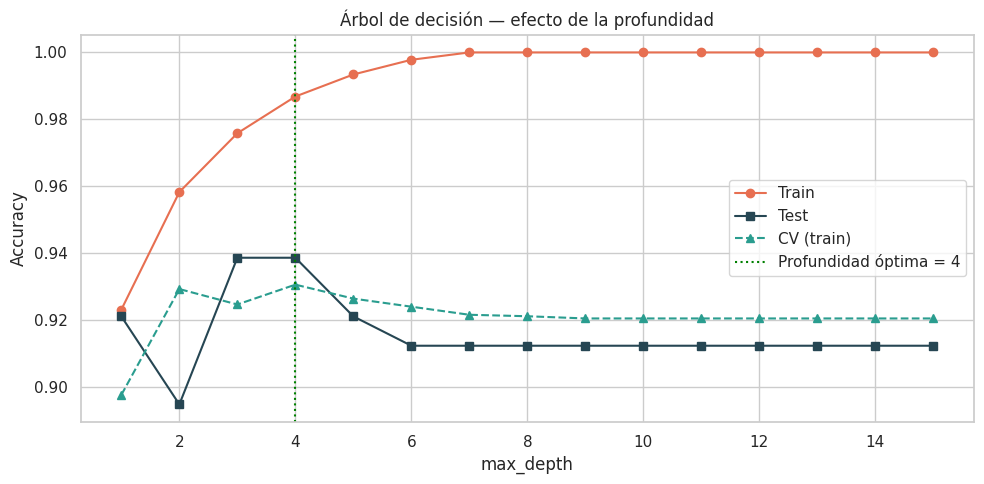

In [21]:
Xb_tr2, Xb_te2, yb_tr2, yb_te2 = train_test_split(bc.data, bc.target, test_size=0.2, random_state=42, stratify=bc.target)

profs = range(1, 16)
acc_tr_d, acc_te_d, acc_cv_d = [], [], []
for d in profs:
    arbol = DecisionTreeClassifier(max_depth=d, random_state=42).fit(Xb_tr2, yb_tr2)
    acc_tr_d.append(arbol.score(Xb_tr2, yb_tr2))
    acc_te_d.append(arbol.score(Xb_te2, yb_te2))
    acc_cv_d.append(cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=42), Xb_tr2, yb_tr2,
                                    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)).mean())

d_opt = list(profs)[int(np.argmax(acc_cv_d))]      # profundidad con mayor accuracy CV (5-fold x 10) sobre train
print('Profundidad óptima (máx. accuracy CV repetida en train): %d' % d_opt)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(profs, acc_tr_d, 'o-', label='Train', color='#e76f51')
ax.plot(profs, acc_te_d, 's-', label='Test', color='#264653')
ax.plot(profs, acc_cv_d, '^--', label='CV (train)', color='#2a9d8f')
ax.axvline(d_opt, color='green', linestyle=':', label='Profundidad óptima = %d' % d_opt)
ax.set_xlabel('max_depth'); ax.set_ylabel('Accuracy'); ax.set_title('Árbol de decisión — efecto de la profundidad')
ax.legend(); plt.tight_layout(); plt.show()

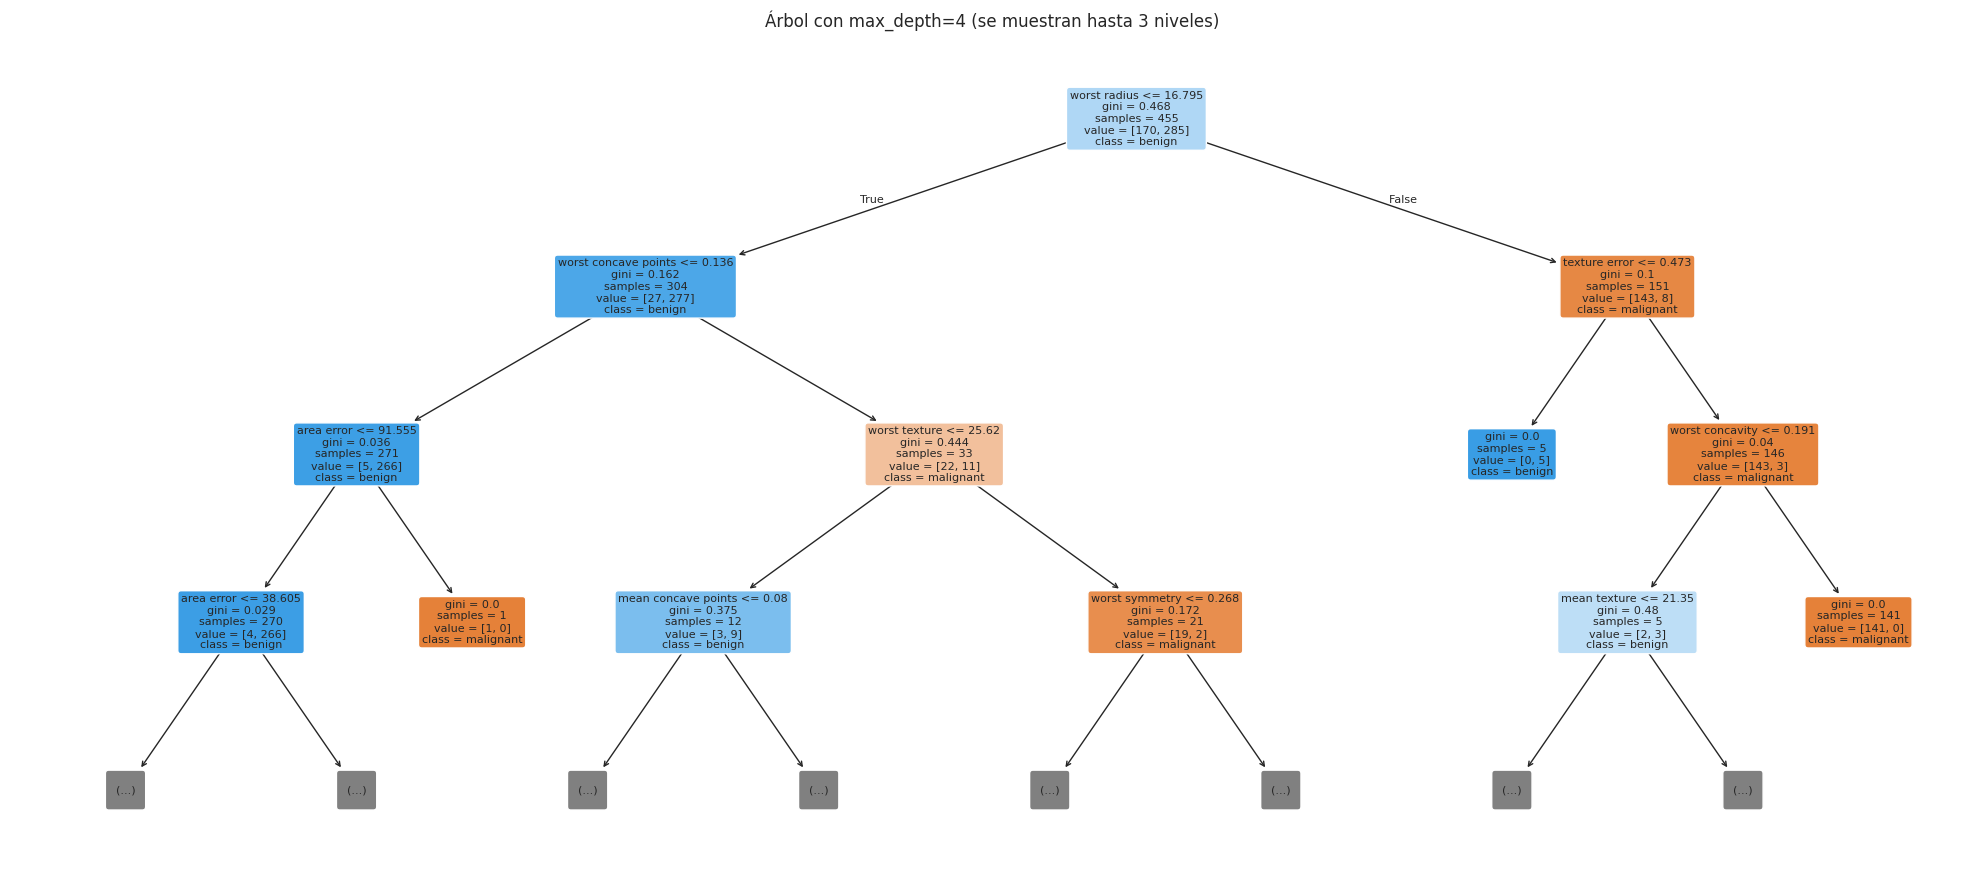

Accuracy test del árbol óptimo: 0.9386


In [22]:
# 4. Visualización del árbol con la profundidad óptima
arbol_opt = DecisionTreeClassifier(max_depth=d_opt, random_state=42).fit(Xb_tr2, yb_tr2)
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(arbol_opt, feature_names=bc.feature_names, class_names=bc.target_names, filled=True,
          rounded=True, fontsize=8, ax=ax, max_depth=3)
ax.set_title('Árbol con max_depth=%d (se muestran hasta 3 niveles)' % d_opt)
plt.tight_layout(); plt.show()
print('Accuracy test del árbol óptimo: %.4f' % arbol_opt.score(Xb_te2, yb_te2))

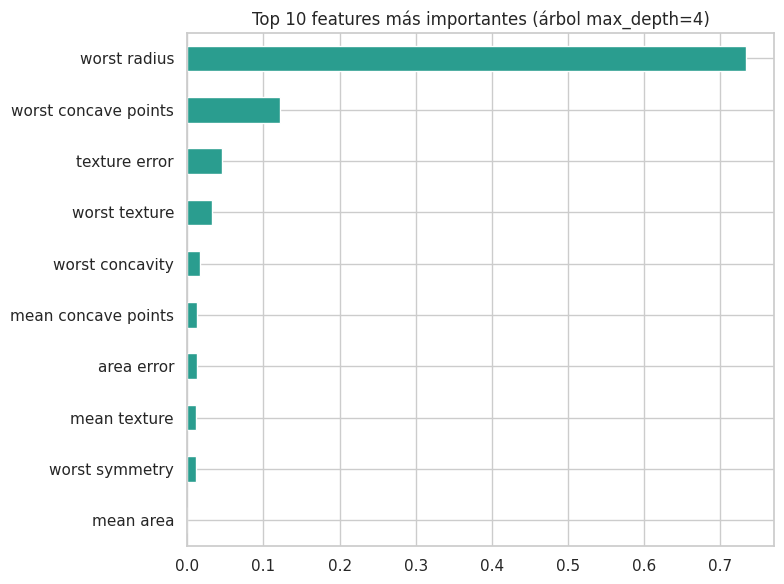

Las 5 features más importantes:
   worst radius              0.734
   worst concave points      0.122
   texture error             0.046
   worst texture             0.032
   worst concavity           0.017


In [23]:
# 5-6. Importancia de features
imp = pd.Series(arbol_opt.feature_importances_, index=bc.feature_names).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6))
imp.head(10).sort_values().plot.barh(ax=ax, color='#2a9d8f')
ax.set_title('Top 10 features más importantes (árbol max_depth=%d)' % d_opt)
plt.tight_layout(); plt.show()
print('Las 5 features más importantes:')
for nombre, v in imp.head(5).items():
    print('   %-25s %.3f' % (nombre, v))

#### Respuesta
- **Punto de inflexión:** el accuracy en train sube hasta 1.000 desde max_depth = 7, mientras que el de test y el de CV se estancan (≈ 0.91–0.93) y luego bajan ligeramente: ese es el sobreajuste. La profundidad óptima por CV repetida es **4** (accuracy CV ≈ 0.931; accuracy en test = 0.939). Con profundidad 1 el árbol subajusta (≈ 0.90 en CV).
- **Las 5 features más importantes** del árbol óptimo: `worst radius` (0.73), `worst concave points` (0.12), `texture error` (0.05), `worst texture` (0.03) y `worst concavity` (0.02). Es decir, el tamaño del núcleo y la presencia de concavidades en el contorno son los mejores indicadores para separar tumores malignos de benignos.
- *Cautela:* la importancia de un solo árbol es inestable (si dos features están muy correlacionadas, el árbol elige una y la otra queda en ≈ 0, como `mean area` o `mean perimeter`, que están muy correlacionadas con `worst radius`).

---
## Nivel 3: Avanzado (Pipelines, CV, tuning)

### Ejercicio 3.1 — Pipeline completo con Cross-Validation
**Dataset:** Wine Quality Red de UCI (descargar desde sklearn o seaborn)

**Tareas:**
1. Cargar el dataset y binarizar el target: calidad ≥ 7 = "bueno", calidad < 7 = "regular"
2. Verificar el desbalance de clases y comentar
3. Crear pipelines con StandardScaler + cada uno de los 4 modelos (LogReg, Árbol, SVM, KNN)
4. Evaluar cada pipeline con cross_val_score (5-fold, scoring='f1')
5. Crear un boxplot comparativo de los F1-scores por fold
6. Seleccionar el mejor modelo y entrenar en todo el train set
7. Evaluar en test: classification_report, matriz de confusión y accuracy

**Entregable:** Notebook con pipeline, CV y selección documentada.

#### Solución

In [24]:
# 1. Carga del Wine Quality (Red) — UCI; si la URL de UCI no responde, se usa una copia del mismo archivo en GitHub
URLS_WQ = [
    'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv',
    'https://raw.githubusercontent.com/shrikant-temburwar/Wine-Quality-Dataset/master/winequality-red.csv',
]
df_wq = None
for u in URLS_WQ:
    try:
        df_wq = pd.read_csv(u, sep=';')
        print('Datos cargados desde:', u)
        break
    except Exception as e:
        print('No se pudo cargar desde', u, '->', type(e).__name__)
assert df_wq is not None, 'No se pudo descargar Wine Quality'

df_wq['calidad_bin'] = (df_wq['quality'] >= 7).astype(int)    # 1 = bueno (>=7), 0 = regular (<7)
print('\nRegistros:', len(df_wq))
print(df_wq['calidad_bin'].value_counts().rename({0: 'regular (<7)', 1: 'bueno (>=7)'}))
print('Proporción de vinos "buenos": %.1f%%' % (100 * df_wq['calidad_bin'].mean()))

No se pudo cargar desde https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv -> URLError


Datos cargados desde: https://raw.githubusercontent.com/shrikant-temburwar/Wine-Quality-Dataset/master/winequality-red.csv

Registros: 1599
calidad_bin
regular (<7)    1382
bueno (>=7)      217
Name: count, dtype: int64
Proporción de vinos "buenos": 13.6%


In [25]:
# 3-4. Pipelines (StandardScaler + modelo) y validación cruzada 5-fold con F1
X_wq = df_wq.drop(columns=['quality', 'calidad_bin'])
y_wq = df_wq['calidad_bin']
Xwq_tr, Xwq_te, ywq_tr, ywq_te = train_test_split(X_wq, y_wq, test_size=0.2, random_state=42, stratify=y_wq)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
pipes_wq = {
    'Regresión Logística': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Árbol de Decisión': make_pipeline(StandardScaler(), DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)),
    'SVM (RBF)': make_pipeline(StandardScaler(), SVC(kernel='rbf', class_weight='balanced')),
    'KNN (K=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
}
f1_cv = {}
for nombre, pipe in pipes_wq.items():
    f1_cv[nombre] = cross_val_score(pipe, Xwq_tr, ywq_tr, cv=cv5, scoring='f1')
    print('%-22s F1 CV = %.4f ± %.4f' % (nombre, f1_cv[nombre].mean(), f1_cv[nombre].std()))

Regresión Logística    F1 CV = 0.5045 ± 0.0355


Árbol de Decisión      F1 CV = 0.5040 ± 0.0462


SVM (RBF)              F1 CV = 0.5246 ± 0.0427


KNN (K=5)              F1 CV = 0.4116 ± 0.0523


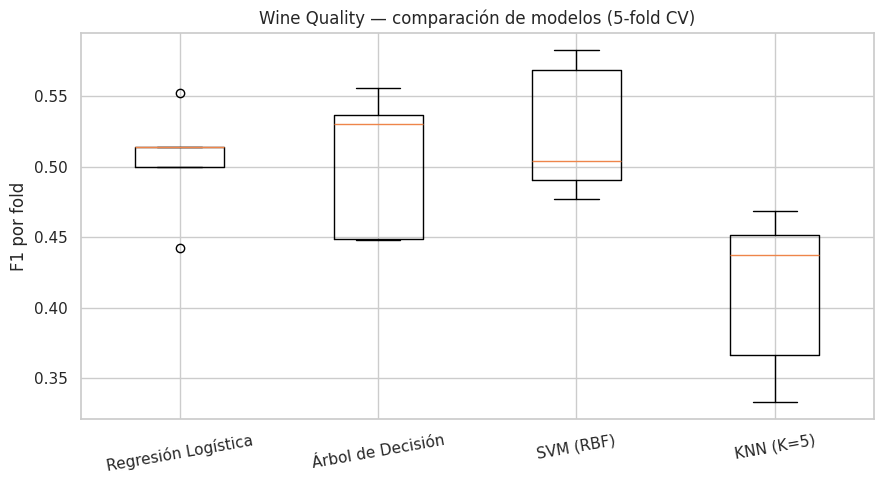

In [26]:
# 5. Boxplot comparativo de F1 por fold
fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot(list(f1_cv.values()), tick_labels=list(f1_cv.keys()))
ax.set_ylabel('F1 por fold'); ax.set_title('Wine Quality — comparación de modelos (5-fold CV)')
plt.xticks(rotation=10); plt.tight_layout(); plt.show()

Mejor modelo según F1 en CV: SVM (RBF)
Accuracy en test: 0.8469

              precision    recall  f1-score   support

regular (<7)      0.960     0.859     0.907       277
 bueno (>=7)      0.458     0.767     0.574        43

    accuracy                          0.847       320
   macro avg      0.709     0.813     0.740       320
weighted avg      0.892     0.847     0.862       320



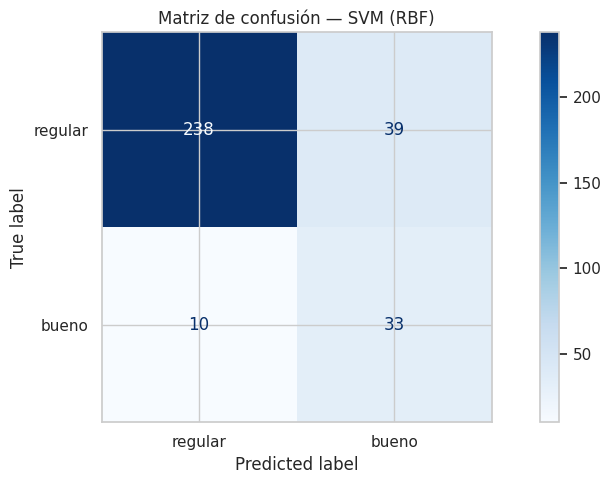

In [27]:
# 6-7. Mejor modelo -> entrenar en todo el train -> evaluar en test
mejor_wq = max(f1_cv, key=lambda k: f1_cv[k].mean())
modelo_wq = pipes_wq[mejor_wq].fit(Xwq_tr, ywq_tr)
pred_wq = modelo_wq.predict(Xwq_te)
print('Mejor modelo según F1 en CV: %s' % mejor_wq)
print('Accuracy en test: %.4f\n' % accuracy_score(ywq_te, pred_wq))
print(classification_report(ywq_te, pred_wq, target_names=['regular (<7)', 'bueno (>=7)'], digits=3))
ConfusionMatrixDisplay.from_predictions(ywq_te, pred_wq, display_labels=['regular', 'bueno'], cmap='Blues')
plt.title('Matriz de confusión — %s' % mejor_wq); plt.tight_layout(); plt.show()

#### Respuesta
**Desbalance:** hay 217 vinos "buenos" (≥ 7) frente a 1 382 "regulares": solo el **13.6 %** es la clase de interés. Un modelo que dijera siempre "regular" tendría 86 % de accuracy sin detectar ningún vino bueno, por eso se evalúa con **F1** (no accuracy), se usa validación cruzada estratificada y `class_weight='balanced'` en los modelos que lo admiten (KNN no lo tiene).

**Resultados en CV (F1, 5-fold):** SVM-RBF 0.525 ± 0.043 · Regresión Logística 0.505 ± 0.036 · Árbol 0.504 ± 0.046 · KNN 0.412 ± 0.052. El mejor es **SVM-RBF**, aunque su ventaja sobre la Logística y el Árbol está dentro de la desviación entre folds (no es una diferencia concluyente); KNN es claramente el peor.

**En test (SVM-RBF):** accuracy 0.847; para la clase "bueno" recall 0.767, precision 0.458 y F1 0.574. El modelo detecta ≈ 77 % de los vinos buenos pero a costa de muchos falsos positivos (solo 46 % de los que marca como buenos lo son): un problema difícil con las 11 variables fisicoquímicas.

### Ejercicio 3.2 — GridSearchCV para optimizar SVM
**Dataset:** `sklearn.datasets.load_breast_cancer()`

**Tareas:**
1. Crear un pipeline: StandardScaler → SVC
2. Definir un grid de hiperparámetros:
   - C: [0.01, 0.1, 1, 10, 100]
   - kernel: ['linear', 'rbf']
   - gamma: ['scale', 0.001, 0.01, 0.1, 1] (solo para RBF)
3. Ejecutar GridSearchCV con cv=5 y scoring='f1'
4. Reportar los mejores hiperparámetros y el mejor F1-score (CV)
5. Evaluar el mejor modelo en test
6. Crear un heatmap de F1-scores para las combinaciones de C y gamma (kernel RBF)

**Entregable:** Notebook con grid search, heatmap y análisis.

#### Solución

In [28]:
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(bc.data, bc.target, test_size=0.2, random_state=42, stratify=bc.target)

pipe_svm = Pipeline([('scaler', StandardScaler()), ('svc', SVC())])
# gamma solo se explora para RBF (el kernel lineal no lo usa) -> dos sub-grillas
param_grid = [
    {'svc__kernel': ['linear'], 'svc__C': [0.01, 0.1, 1, 10, 100]},
    {'svc__kernel': ['rbf'], 'svc__C': [0.01, 0.1, 1, 10, 100], 'svc__gamma': ['scale', 0.001, 0.01, 0.1, 1]},
]
gs = GridSearchCV(pipe_svm, param_grid, cv=5, scoring='f1', n_jobs=-1, return_train_score=False)
gs.fit(Xg_tr, yg_tr)
print('Combinaciones evaluadas:', len(gs.cv_results_['params']))
print('Mejores hiperparámetros:', gs.best_params_)
print('Mejor F1 (CV): %.4f' % gs.best_score_)

Combinaciones evaluadas: 30
Mejores hiperparámetros: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Mejor F1 (CV): 0.9844


In [29]:
# 5. Evaluación del mejor modelo en test
y_pred_g = gs.best_estimator_.predict(Xg_te)
print('Accuracy test: %.4f | F1 test: %.4f\n' % (accuracy_score(yg_te, y_pred_g), f1_score(yg_te, y_pred_g)))
print(classification_report(yg_te, y_pred_g, target_names=bc.target_names, digits=3))

Accuracy test: 0.9825 | F1 test: 0.9861

              precision    recall  f1-score   support

   malignant      0.976     0.976     0.976        42
      benign      0.986     0.986     0.986        72

    accuracy                          0.982       114
   macro avg      0.981     0.981     0.981       114
weighted avg      0.982     0.982     0.982       114



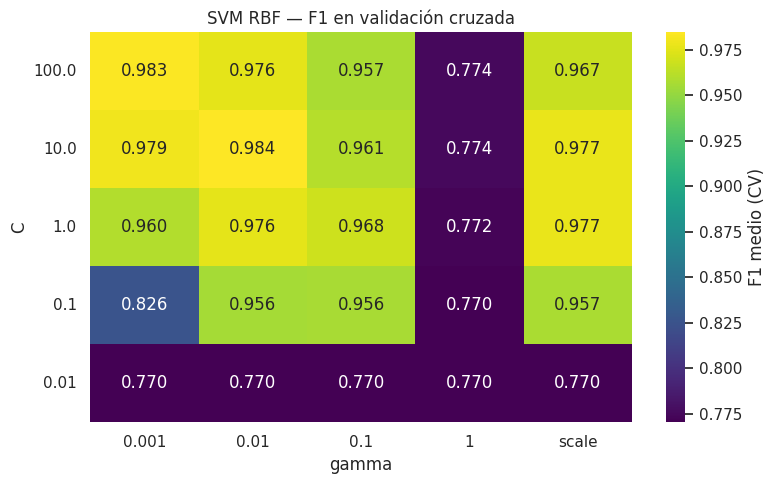

In [30]:
# 6. Heatmap de F1 (CV) para C x gamma con kernel RBF
res = pd.DataFrame(gs.cv_results_)
rbf = res[res['param_svc__kernel'] == 'rbf'].copy()
rbf['gamma'] = rbf['param_svc__gamma'].astype(str)
pivote = rbf.pivot(index='param_svc__C', columns='gamma', values='mean_test_score')
pivote = pivote[['0.001', '0.01', '0.1', '1', 'scale']]          # orden numérico, 'scale' al final
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivote, annot=True, fmt='.3f', cmap='viridis', ax=ax, cbar_kws={'label': 'F1 medio (CV)'})
ax.set_xlabel('gamma'); ax.set_ylabel('C'); ax.set_title('SVM RBF — F1 en validación cruzada')
ax.invert_yaxis(); plt.yticks(rotation=0); plt.tight_layout(); plt.show()

#### Respuesta
- **Mejores hiperparámetros:** kernel RBF, **C = 10**, **gamma = 0.01**, con F1 medio en CV = **0.984**. En test: accuracy 0.983 y F1 0.986.
- **Lectura del heatmap:** (i) `gamma = 1` colapsa (F1 ≈ 0.77) para cualquier C: el kernel es tan "estrecho" que el modelo memoriza y termina prediciendo la clase mayoritaria; (ii) `C = 0.01` regulariza tanto que también se queda en ≈ 0.77 (subajuste); (iii) la región buena (F1 ≈ 0.96–0.98) es amplia: C entre 1 y 100 con gamma entre 0.001 y 0.1 o `'scale'` (≈ 0.033 con datos estandarizados). Es un buen ejemplo de la interacción C–gamma.

### Ejercicio 3.3 — Manejo de clases desbalanceadas
**Dataset:** Crear un dataset desbalanceado con `make_classification`

**Tareas:**
1. Generar 1000 muestras con `make_classification(n_classes=2, weights=[0.95, 0.05])` (95% vs 5%)
2. Entrenar una Regresión Logística SIN manejar el desbalance → reportar accuracy, precision, recall, F1
3. Entrenar con `class_weight='balanced'` → comparar métricas
4. Responder: ¿Por qué la accuracy es alta incluso sin balancear? ¿Qué métrica revela el problema?
5. Graficar las curvas Precision-Recall para ambos modelos
6. Repetir usando SMOTE de `imbalanced-learn` (si está disponible en Colab) y comparar

**Entregable:** Comparación de 3 estrategias con métricas y gráficos.

#### Solución

In [31]:
import subprocess, sys
try:
    import imblearn
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'], check=False)
    import imblearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.datasets import make_classification

# 1. Dataset desbalanceado 95% / 5%
Xi, yi = make_classification(n_samples=1000, n_features=20, n_informative=5, n_redundant=2,
                             n_classes=2, weights=[0.95, 0.05], flip_y=0.01, class_sep=1.5, random_state=42)
print('Distribución de clases:', dict(zip(*np.unique(yi, return_counts=True))))
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.3, random_state=42, stratify=yi)

Distribución de clases: {np.int64(0): np.int64(945), np.int64(1): np.int64(55)}


In [32]:
# 2-3 y 6. Tres estrategias: sin balancear, class_weight='balanced' y SMOTE (solo sobre el train)
estrategias = {
    'Sin balancear': LogisticRegression(max_iter=2000),
    "class_weight='balanced'": LogisticRegression(max_iter=2000, class_weight='balanced'),
    'SMOTE + LogReg': ImbPipeline([('smote', SMOTE(random_state=42)), ('clf', LogisticRegression(max_iter=2000))]),
}
filas = []
for nombre, mod in estrategias.items():
    mod.fit(Xi_tr, yi_tr)
    p = mod.predict(Xi_te)
    prob = mod.predict_proba(Xi_te)[:, 1]
    filas.append({'Estrategia': nombre,
                  'Accuracy': accuracy_score(yi_te, p),
                  'Precision': precision_score(yi_te, p, zero_division=0),
                  'Recall': recall_score(yi_te, p),
                  'F1': f1_score(yi_te, p),
                  'Avg. Precision (PR-AUC)': average_precision_score(yi_te, prob)})
tabla_imb = pd.DataFrame(filas).set_index('Estrategia')
display(tabla_imb.round(4))
print('Accuracy de un clasificador "tonto" que siempre predice la clase mayoritaria: %.4f' % (1 - yi_te.mean()))

,Accuracy,Precision,Recall,F1,Avg. Precision (PR-AUC)
Estrategia,,,,,
Sin balancear,0.9500,0.6000,0.1875,0.2857,0.5571
class_weight='balanced',0.8467,0.2500,0.9375,0.3947,0.2922
SMOTE + LogReg,0.8500,0.2456,0.8750,0.3836,0.3268


Accuracy de un clasificador "tonto" que siempre predice la clase mayoritaria: 0.9467


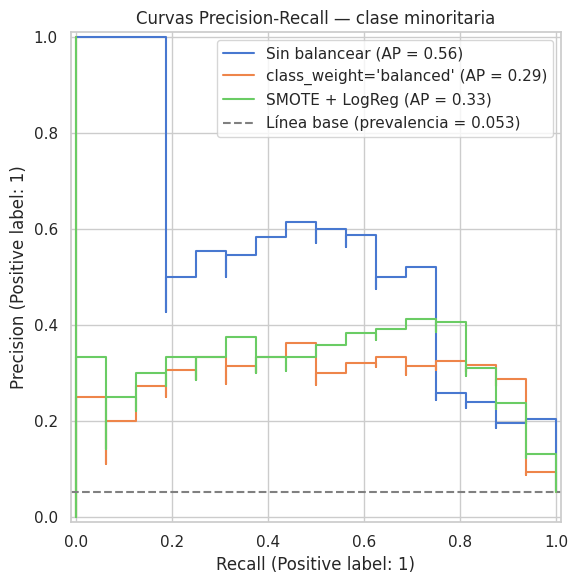

In [33]:
# 5. Curvas Precision-Recall de las tres estrategias
fig, ax = plt.subplots(figsize=(8, 6))
for nombre, mod in estrategias.items():
    PrecisionRecallDisplay.from_estimator(mod, Xi_te, yi_te, ax=ax, name=nombre)
ax.axhline(yi_te.mean(), color='gray', linestyle='--', label='Línea base (prevalencia = %.3f)' % yi_te.mean())
ax.set_title('Curvas Precision-Recall — clase minoritaria'); ax.legend(loc='upper right')
plt.tight_layout(); plt.show()

#### Respuesta
| Estrategia | Accuracy | Precision | Recall | F1 | PR-AUC |
|---|---|---|---|---|---|
| Sin balancear | **0.950** | 0.600 | 0.188 | 0.286 | 0.557 |
| `class_weight='balanced'` | 0.847 | 0.250 | 0.938 | 0.395 | 0.292 |
| SMOTE + LogReg | 0.850 | 0.246 | 0.875 | 0.384 | 0.327 |

**¿Por qué la accuracy es alta incluso sin balancear?** Porque el 94.7 % de los casos son de la clase mayoritaria: predecir siempre "0" daría 0.947 de accuracy, y el modelo sin balancear (0.950) apenas la supera mientras detecta solo 3 de 16 casos positivos. **La métrica que revela el problema es el recall de la clase minoritaria** (0.19), y con él el F1 y la curva Precision-Recall; la accuracy oculta el fallo.

**Comparación de estrategias:** `class_weight='balanced'` y SMOTE llevan el recall a 0.94 y 0.88 (se detectan casi todos los positivos), pero la precisión cae a ≈ 0.25 (muchos falsos positivos) y la accuracy baja a ≈ 0.85; el F1 mejora de 0.29 a ≈ 0.39. Es decir, **balancear desplaza el compromiso precision/recall, no crea información nueva**: el PR-AUC (calidad del ranking) no mejora. Elegir entre ellas depende del costo de cada error. Con solo 16 positivos en test, las diferencias entre las dos técnicas de balanceo no son concluyentes.

### Ejercicio 3.4 — Heart Disease: Proyecto mini completo
**Dataset:** Heart Disease UCI (cargar desde CSV o usar la versión de sklearn/kaggle)

**Tareas:**
1. **Exploración:** estadísticas, distribuciones, correlaciones, valores faltantes
2. **Preprocesamiento:** manejar valores faltantes (si los hay), estandarizar features numéricas
3. **Modelado:** entrenar al menos 3 modelos dentro de pipelines
4. **Evaluación:** cross-validation (F1), matrices de confusión, curvas ROC
5. **Tuning:** GridSearchCV para el mejor modelo
6. **Selección:** justificar la elección del modelo final
7. **Interpretación:** ¿Qué features son más importantes para predecir enfermedad cardíaca?

**Restricción:** Toda la evaluación debe considerar que un falso negativo (no detectar la enfermedad) es más costoso que un falso positivo.

**Entregable:** Notebook completo tipo proyecto, con narrativa explicando cada decisión.

#### Solución

In [34]:
# Carga: se prueba la URL de la sesión 1; si no responde, copias del mismo dataset (Cleveland, 303 pacientes) y, al final, OpenML
URLS_HEART = [
    'https://raw.githubusercontent.com/reddyprasade/Machine-Learning/master/Heart-Disease-UCI/heart.csv',
    'https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv',
    'https://raw.githubusercontent.com/sharmaroshan/Heart-UCI-Dataset/master/heart.csv',
]
df_h = None
for u in URLS_HEART:
    try:
        df_h = pd.read_csv(u)
        print('Datos cargados desde:', u)
        break
    except Exception as e:
        print('No disponible:', u, '->', type(e).__name__)
if df_h is None:
    from sklearn.datasets import fetch_openml
    b = fetch_openml(data_id=1574, as_frame=True)
    df_h = b.frame.rename(columns={'class': 'target'})
    print('Datos cargados desde OpenML')
print('Dimensiones:', df_h.shape)
display(df_h.head())

No disponible: https://raw.githubusercontent.com/reddyprasade/Machine-Learning/master/Heart-Disease-UCI/heart.csv -> HTTPError
Datos cargados desde: https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv
Dimensiones: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [35]:
# 1. EXPLORACIÓN
print('Valores faltantes por columna:'); print(df_h.isna().sum()[df_h.isna().sum() > 0] if df_h.isna().any().any() else 'Ninguno (NaN explícitos)')
print('\nDistribución del target (1 = enfermedad):'); print(df_h['target'].value_counts().rename({0: 'sin enfermedad', 1: 'con enfermedad'}))
display(df_h.describe().T.round(2))

# Códigos "imposibles" que en este dataset representan datos faltantes: ca=4 y thal=0
print('\nca == 4 :', int((df_h['ca'] == 4).sum()), 'filas  |  thal == 0 :', int((df_h['thal'] == 0).sum()), 'filas')

Valores faltantes por columna:
Ninguno (NaN explícitos)

Distribución del target (1 = enfermedad):
target
con enfermedad    165
sin enfermedad    138
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.37,9.08,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.97,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.62,17.54,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.26,51.83,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.65,22.91,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2



ca == 4 : 5 filas  |  thal == 0 : 2 filas


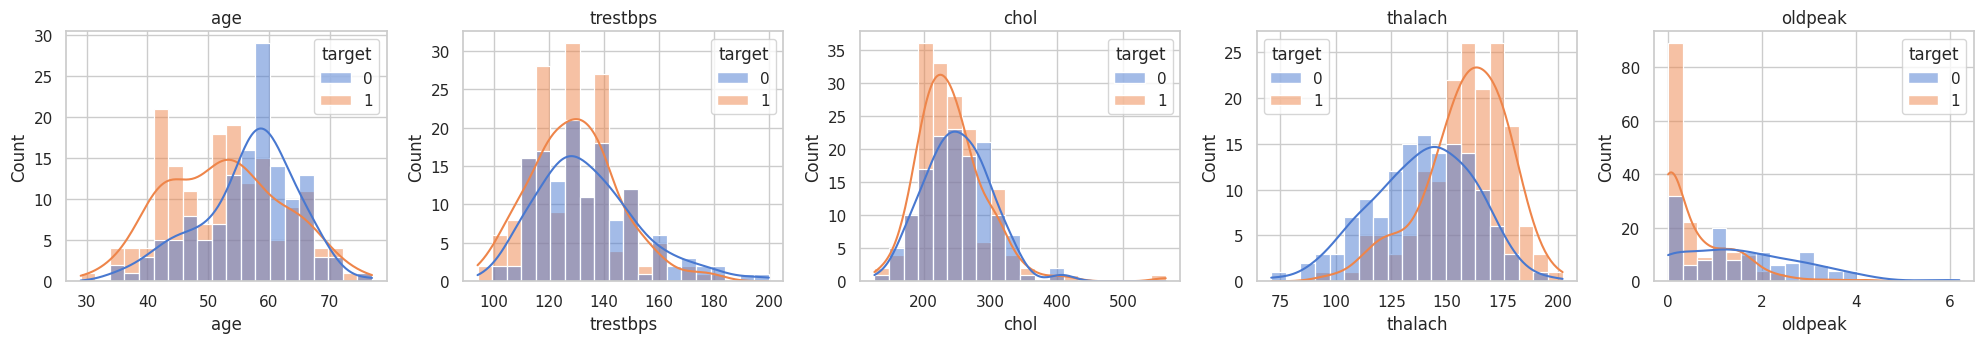

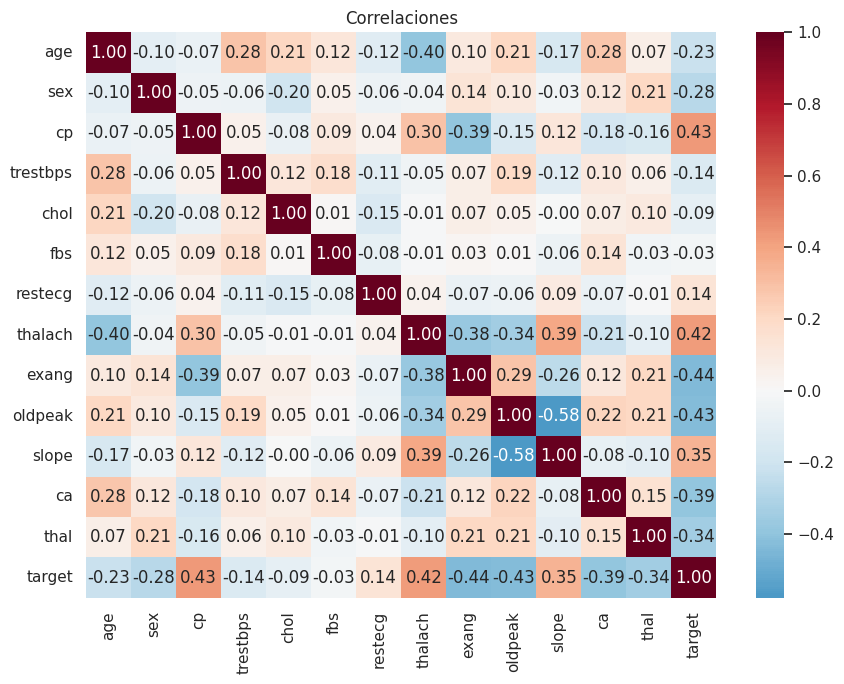

In [36]:
num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(1, 5, figsize=(20, 3.6))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df_h, x=c, hue='target', kde=True, ax=ax, bins=20)
    ax.set_title(c)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df_h.corr(numeric_only=True), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Correlaciones'); plt.tight_layout(); plt.show()

In [37]:
# 2. PREPROCESAMIENTO (todo dentro de un ColumnTransformer -> sin fuga de datos)
df_h = df_h.copy()
df_h.loc[df_h['ca'] == 4, 'ca'] = np.nan          # código inválido -> faltante
df_h.loc[df_h['thal'] == 0, 'thal'] = np.nan      # código inválido -> faltante

cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
X_h, y_h = df_h.drop(columns='target'), df_h['target']
Xh_tr, Xh_te, yh_tr, yh_te = train_test_split(X_h, y_h, test_size=0.2, random_state=42, stratify=y_h)

prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(handle_unknown='ignore'))]), cat_cols),
])
print('Train:', Xh_tr.shape, '| Test:', Xh_te.shape)

Train: (242, 13) | Test: (61, 13)


In [38]:
# 3-4. MODELADO y EVALUACIÓN con validación cruzada. Como un falso negativo es más costoso,
#      además de F1 se reportan Recall y F2 (que pondera el recall el doble que la precisión).
f2 = make_scorer(fbeta_score, beta=2)
modelos_h = {
    'Regresión Logística': Pipeline([('prep', prep), ('clf', LogisticRegression(max_iter=2000))]),
    'SVM (RBF)': Pipeline([('prep', prep), ('clf', SVC(kernel='rbf', probability=True, random_state=42))]),
    'KNN': Pipeline([('prep', prep), ('clf', KNeighborsClassifier(n_neighbors=9))]),
    'Random Forest': Pipeline([('prep', prep), ('clf', RandomForestClassifier(n_estimators=300, random_state=42))]),
}
cvh = StratifiedKFold(5, shuffle=True, random_state=42)
filas = []
for nombre, mod in modelos_h.items():
    r = cross_validate(mod, Xh_tr, yh_tr, cv=cvh,
                       scoring={'f1': 'f1', 'recall': 'recall', 'f2': f2, 'roc_auc': 'roc_auc'})
    filas.append({'Modelo': nombre, 'F1': r['test_f1'].mean(), 'Recall': r['test_recall'].mean(),
                  'F2': r['test_f2'].mean(), 'ROC-AUC': r['test_roc_auc'].mean()})
res_h = pd.DataFrame(filas).set_index('Modelo')
display(res_h.round(4))

,F1,Recall,F2,ROC-AUC
Modelo,,,,
Regresión Logística,0.8377,0.8405,0.8390,0.8935
SVM (RBF),0.8285,0.8256,0.8266,0.8896
KNN,0.8442,0.8632,0.8555,0.8922
Random Forest,0.8301,0.8330,0.8317,0.8900


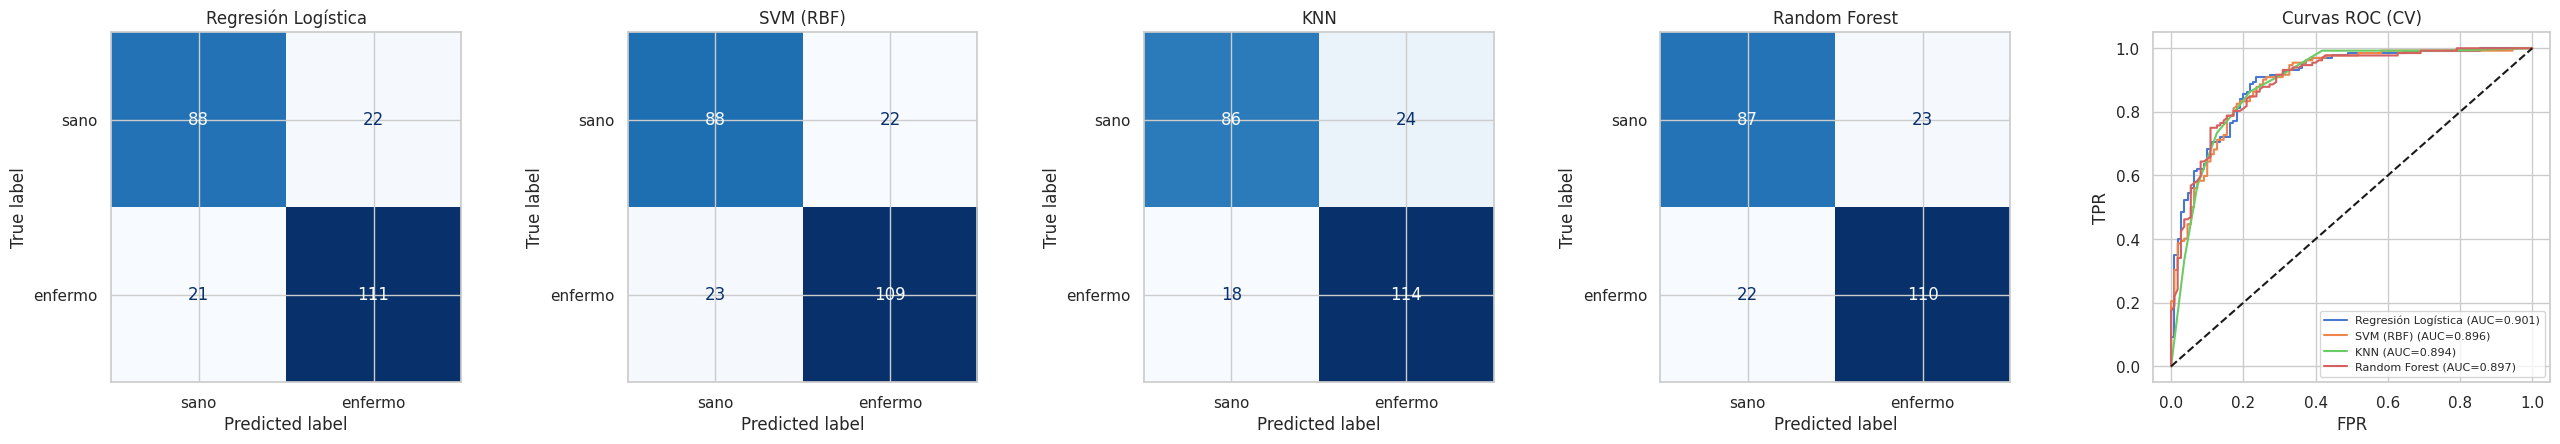

In [39]:
# Matrices de confusión y curvas ROC con predicciones "out-of-fold" (cada paciente se predice sin haber sido visto en el entrenamiento)
fig, axes = plt.subplots(1, 5, figsize=(26, 4.6))
for ax, (nombre, mod) in zip(axes[:4], modelos_h.items()):
    p = cross_val_predict(mod, Xh_tr, yh_tr, cv=cvh)
    ConfusionMatrixDisplay.from_predictions(yh_tr, p, display_labels=['sano', 'enfermo'], cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(nombre)
for nombre, mod in modelos_h.items():
    pr = cross_val_predict(mod, Xh_tr, yh_tr, cv=cvh, method='predict_proba')[:, 1]
    fpr, tpr, _ = roc_curve(yh_tr, pr)
    axes[4].plot(fpr, tpr, label='%s (AUC=%.3f)' % (nombre, roc_auc_score(yh_tr, pr)))
axes[4].plot([0, 1], [0, 1], 'k--'); axes[4].set_title('Curvas ROC (CV)'); axes[4].legend(fontsize=8)
axes[4].set_xlabel('FPR'); axes[4].set_ylabel('TPR')
plt.tight_layout(); plt.show()

In [40]:
# 5. TUNING con GridSearchCV sobre el mejor modelo según F2
mejor_h = res_h['F2'].idxmax()
print('Mejor modelo base según F2:', mejor_h)
grillas = {
    'Regresión Logística': {'clf__C': [0.01, 0.1, 1, 10], 'clf__class_weight': [None, 'balanced']},
    'SVM (RBF)': {'clf__C': [0.1, 1, 10], 'clf__gamma': ['scale', 0.01, 0.1], 'clf__class_weight': [None, 'balanced']},
    'KNN': {'clf__n_neighbors': [3, 5, 7, 9, 11, 15], 'clf__weights': ['uniform', 'distance']},
    'Random Forest': {'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 5, None], 'clf__min_samples_leaf': [1, 3, 5],
                      'clf__class_weight': [None, 'balanced']},
}
gs_h = GridSearchCV(modelos_h[mejor_h], grillas[mejor_h], cv=cvh, scoring=f2, n_jobs=-1)
gs_h.fit(Xh_tr, yh_tr)
print('Mejores hiperparámetros:', gs_h.best_params_)
print('Mejor F2 (CV): %.4f' % gs_h.best_score_)

Mejor modelo base según F2: KNN


Mejores hiperparámetros: {'clf__n_neighbors': 15, 'clf__weights': 'uniform'}
Mejor F2 (CV): 0.8754


Umbral óptimo (mínimo costo en train, FN=5 x FP): 0.21   (el umbral por defecto es 0.50)


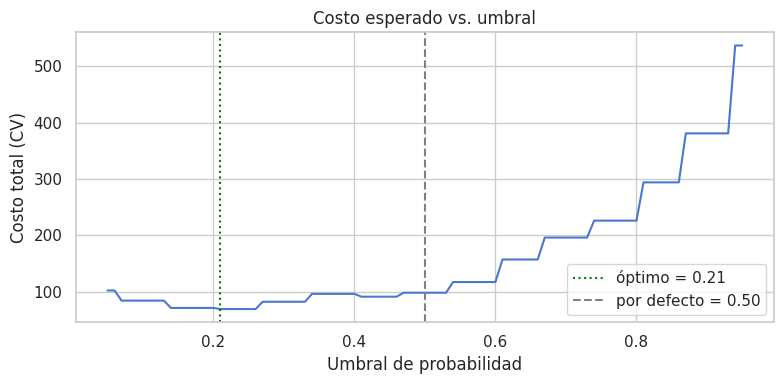

In [41]:
# 6. SELECCIÓN FINAL con criterio de costo: un falso negativo cuesta 5 veces un falso positivo.
#    El umbral de decisión se elige con probabilidades out-of-fold del TRAIN (nunca con el test).
COSTO_FN, COSTO_FP = 5, 1
prob_oof = cross_val_predict(gs_h.best_estimator_, Xh_tr, yh_tr, cv=cvh, method='predict_proba')[:, 1]
umbrales = np.linspace(0.05, 0.95, 91)
def costo_total(y_true, prob, t):
    p = (prob >= t).astype(int)
    fn = ((y_true == 1) & (p == 0)).sum(); fp = ((y_true == 0) & (p == 1)).sum()
    return COSTO_FN * fn + COSTO_FP * fp
costos = [costo_total(yh_tr.values, prob_oof, t) for t in umbrales]
t_opt = umbrales[int(np.argmin(costos))]
print('Umbral óptimo (mínimo costo en train, FN=%d x FP): %.2f   (el umbral por defecto es 0.50)' % (COSTO_FN, t_opt))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(umbrales, costos); ax.axvline(t_opt, color='green', linestyle=':', label='óptimo = %.2f' % t_opt)
ax.axvline(0.5, color='gray', linestyle='--', label='por defecto = 0.50')
ax.set_xlabel('Umbral de probabilidad'); ax.set_ylabel('Costo total (CV)'); ax.legend()
ax.set_title('Costo esperado vs. umbral'); plt.tight_layout(); plt.show()

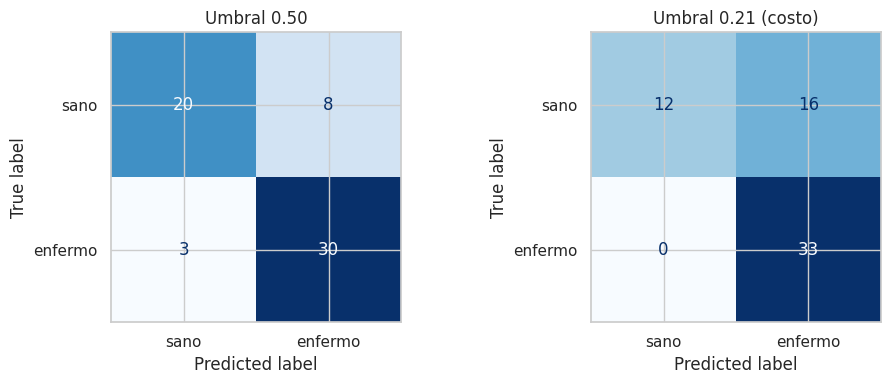

,Recall,Precision,F2,FN,FP,Costo (5*FN + FP)
Configuración,,,,,,
Umbral 0.50,0.909,0.789,0.882,3,8,23
Umbral 0.21 (costo),1.000,0.673,0.912,0,16,16


ROC-AUC en test: 0.9167


In [42]:
# Evaluación final en TEST: umbral por defecto vs. umbral optimizado por costo
final = gs_h.best_estimator_.fit(Xh_tr, yh_tr)
prob_te = final.predict_proba(Xh_te)[:, 1]
filas = []
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (etq, t) in zip(axes, [('Umbral 0.50', 0.5), ('Umbral %.2f (costo)' % t_opt, t_opt)]):
    p = (prob_te >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(yh_te, p).ravel()
    filas.append({'Configuración': etq, 'Recall': recall_score(yh_te, p), 'Precision': precision_score(yh_te, p),
                  'F2': fbeta_score(yh_te, p, beta=2), 'FN': fn, 'FP': fp, 'Costo (5*FN + FP)': COSTO_FN * fn + COSTO_FP * fp})
    ConfusionMatrixDisplay.from_predictions(yh_te, p, display_labels=['sano', 'enfermo'], cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(etq)
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).set_index('Configuración').round(3))
print('ROC-AUC en test: %.4f' % roc_auc_score(yh_te, prob_te))

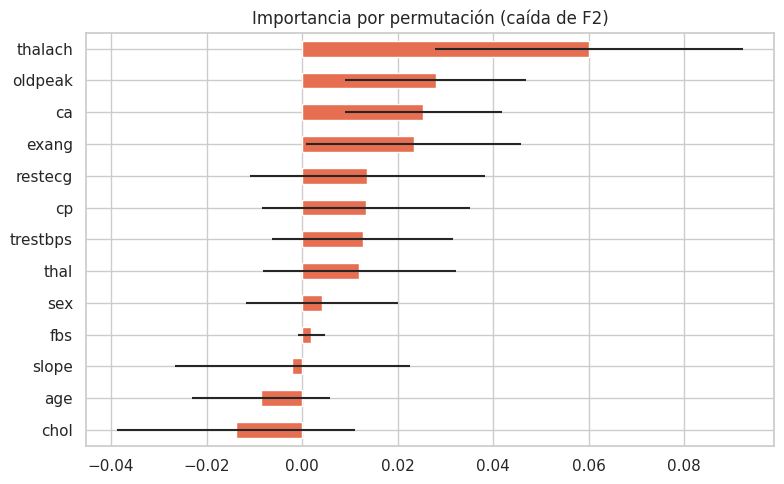

Top 5 features:
thalach    0.0601
oldpeak    0.0279
ca         0.0254
exang      0.0233
restecg    0.0137


In [43]:
# 7. INTERPRETACIÓN: importancia por permutación sobre las columnas originales (en test)
pi = permutation_importance(final, Xh_te, yh_te, scoring=f2, n_repeats=30, random_state=42)
imp_h = pd.Series(pi.importances_mean, index=Xh_te.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5))
imp_h.sort_values().plot.barh(ax=ax, xerr=pd.Series(pi.importances_std, index=Xh_te.columns)[imp_h.sort_values().index],
                              color='#e76f51')
ax.set_title('Importancia por permutación (caída de F2)'); plt.tight_layout(); plt.show()
print('Top 5 features:'); print(imp_h.head(5).round(4).to_string())

#### Narrativa y decisiones
1. **Exploración:** 303 pacientes, 165 con enfermedad (54 %), sin NaN explícitos; pero hay códigos imposibles que en este dataset representan datos faltantes (`ca = 4` en 5 filas y `thal = 0` en 2 filas), que se convirtieron en `NaN` y se imputan.
2. **Preprocesamiento:** dentro de un `ColumnTransformer` (sin fuga de datos): numéricas con mediana + estandarización; categóricas con moda + One-Hot.
3. **Modelos y evaluación (CV 5-fold en train).** Como un falso negativo es más costoso, además de F1 se reportan **Recall y F2** (pondera el recall el doble): Regresión Logística F2 0.839 · SVM 0.827 · **KNN 0.856** · Random Forest 0.832. Las diferencias son pequeñas (1–3 puntos) frente al ruido de un dataset de 242 pacientes de entrenamiento.
4. **Tuning:** `GridSearchCV` (scoring = F2) sobre el mejor modelo (KNN) → `n_neighbors = 15`, F2 CV = 0.875.
5. **Selección del umbral con criterio de costo (FN = 5 × FP):** con probabilidades out-of-fold del train el umbral óptimo bajó de 0.50 a **0.21**. En test (61 pacientes): con 0.50 → recall 0.909, 3 falsos negativos, 8 falsos positivos (costo 23); con 0.21 → **recall 1.00, 0 falsos negativos**, 16 falsos positivos (costo 16) y F2 de 0.88 a 0.91. Es decir, se acepta más falsas alarmas a cambio de no dejar pacientes enfermos sin detectar.
6. **Justificación del modelo final:** KNN afinado + umbral por costo, por tener el mejor F2/recall. Como los cuatro modelos están muy parejos, una alternativa igualmente defendible es la Regresión Logística, más interpretable. *Limitación:* el test tiene solo 61 pacientes, por lo que estas cifras son orientativas.
7. **Interpretación (importancia por permutación, caída de F2):** `thalach` (frecuencia cardíaca máxima, 0.060), `oldpeak` (depresión del ST, 0.028), `ca` (n.º de vasos principales coloreados, 0.025), `exang` (angina inducida por ejercicio, 0.023) y `restecg` (0.014). Es coherente con los factores clínicos conocidos, pero la importancia calculada sobre 61 pacientes es ruidosa.

---
## Nivel 4: Desafío (Integración y pensamiento crítico)

### Ejercicio 4.1 — Comparación justa de modelos con múltiples datasets
**Datasets:** Iris, Wine, Breast Cancer, Digits

**Tareas:**
1. Para cada dataset, entrenar los 4 modelos (LogReg, Árbol, SVM-RBF, KNN) dentro de pipelines
2. Evaluar todos con cross-validation (5-fold, F1-weighted)
3. Crear una tabla de resultados: filas = datasets, columnas = modelos
4. Crear un heatmap de la tabla
5. Responder con argumento:
   - ¿Existe un modelo que sea "el mejor" en todos los datasets?
   - ¿Qué características del dataset favorecen a cada modelo?
   - ¿Qué modelo recomendarías como "primera opción" cuando no se sabe nada del problema?

**Entregable:** Análisis comparativo con tablas, heatmap y argumentación escrita.

#### Solución

In [44]:
datasets_41 = {
    'Iris': datasets.load_iris(return_X_y=True),
    'Wine': datasets.load_wine(return_X_y=True),
    'Breast Cancer': datasets.load_breast_cancer(return_X_y=True),
    'Digits': datasets.load_digits(return_X_y=True),
}
def hacer_pipes():
    return {
        'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
        'Árbol': make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=42)),
        'SVM-RBF': make_pipeline(StandardScaler(), SVC(kernel='rbf')),
        'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    }
cv41 = StratifiedKFold(5, shuffle=True, random_state=42)
medias, desvs = {}, {}
for nom_d, (X41, y41) in datasets_41.items():
    medias[nom_d], desvs[nom_d] = {}, {}
    for nom_m, pipe in hacer_pipes().items():
        s = cross_val_score(pipe, X41, y41, cv=cv41, scoring='f1_weighted')
        medias[nom_d][nom_m], desvs[nom_d][nom_m] = s.mean(), s.std()
tabla_41 = pd.DataFrame(medias).T
print('F1-weighted medio (5-fold CV) — filas: datasets, columnas: modelos')
display(tabla_41.round(4))
print('Desviación estándar entre folds:')
display(pd.DataFrame(desvs).T.round(4))

F1-weighted medio (5-fold CV) — filas: datasets, columnas: modelos


,LogReg,Árbol,SVM-RBF,KNN
Iris,0.9532,0.9531,0.9599,0.9733
Wine,0.9833,0.8985,0.9833,0.9717
Breast Cancer,0.9734,0.9097,0.9771,0.9628
Digits,0.9710,0.8545,0.9839,0.9788


Desviación estándar entre folds:


,LogReg,Árbol,SVM-RBF,KNN
Iris,0.0453,0.0341,0.0389,0.0250
Wine,0.0136,0.0284,0.0222,0.0184
Breast Cancer,0.0170,0.0289,0.0164,0.0181
Digits,0.0038,0.0155,0.0060,0.0063


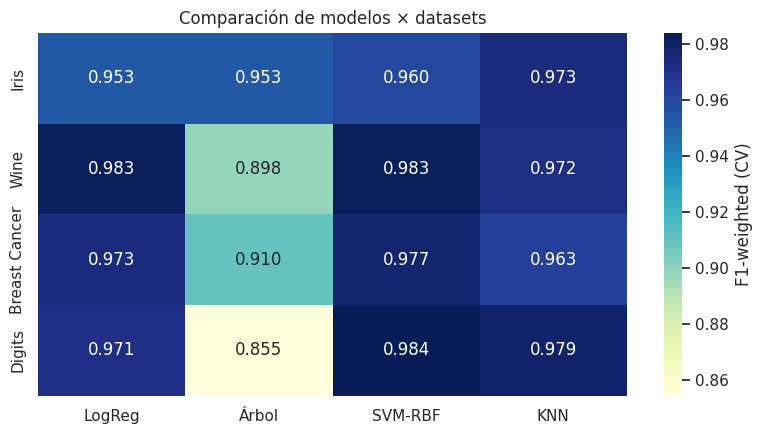

Ranking promedio (1 = mejor):
SVM-RBF    1.50
LogReg     2.25
KNN        2.25
Árbol      4.00

Mejor modelo por dataset:
Iris                 KNN
Wine              LogReg
Breast Cancer    SVM-RBF
Digits           SVM-RBF


In [45]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(tabla_41, annot=True, fmt='.3f', cmap='YlGnBu', ax=ax, cbar_kws={'label': 'F1-weighted (CV)'})
ax.set_title('Comparación de modelos × datasets'); plt.tight_layout(); plt.show()

ranking_41 = tabla_41.rank(axis=1, ascending=False).mean().sort_values()
print('Ranking promedio (1 = mejor):'); print(ranking_41.round(2).to_string())
print('\nMejor modelo por dataset:'); print(tabla_41.idxmax(axis=1).to_string())

#### Respuesta
| F1-weighted (CV) | LogReg | Árbol | SVM-RBF | KNN |
|---|---|---|---|---|
| Iris | 0.953 | 0.953 | 0.960 | **0.973** |
| Wine | **0.983** | 0.899 | **0.983** | 0.972 |
| Breast Cancer | 0.973 | 0.910 | **0.977** | 0.963 |
| Digits | 0.971 | 0.855 | **0.984** | 0.979 |

**¿Existe un modelo "el mejor" en todos los datasets?** No: gana KNN en Iris, LogReg (empatado con SVM) en Wine y SVM-RBF en Breast Cancer y Digits. El SVM-RBF tiene el mejor ranking promedio (1.5), seguido de LogReg y KNN (2.25) y, a distancia, el árbol (4.0). En Iris las diferencias (≈ 0.01–0.02) son menores que la desviación entre folds (0.025–0.045), así que no son concluyentes.

**¿Qué características favorecen a cada modelo?**
- **Regresión Logística:** datos casi linealmente separables y con pocas muestras (Wine, Breast Cancer): compite con los modelos complejos y es más simple e interpretable.
- **SVM-RBF:** fronteras no lineales con suficientes muestras por clase y dimensión alta (Digits: 64 pixeles); es el más consistente.
- **KNN:** funciona bien cuando hay estructura local y datos bien escalados (Iris, Digits), pero se degrada con features irrelevantes (ver ejercicio 4.2).
- **Árbol:** el peor en todos; las divisiones paralelas a los ejes y su alta varianza (sin ensamblado) lo penalizan, sobre todo en Digits (0.855), donde la información está repartida entre muchos píxeles.

**Primera opción sin conocer el problema:** un **SVM-RBF con estandarización** (con `C` y `gamma` afinados), usando Regresión Logística como baseline rápido e interpretable. Siempre dentro de un pipeline y validando con CV.

### Ejercicio 4.2 — Impacto de features irrelevantes
**Dataset:** `sklearn.datasets.load_breast_cancer()`

**Tareas:**
1. Entrenar un SVM (RBF) con las 30 features originales → F1 con CV
2. Añadir 20 features aleatorias (ruido) al dataset → entrenar y reportar F1
3. Añadir 50 features aleatorias → entrenar y reportar F1
4. Graficar F1 vs. número de features ruidosas (0, 10, 20, 30, 40, 50)
5. Repetir el experimento con KNN y Árbol de Decisión
6. Responder: ¿Qué modelo es más robusto al ruido? ¿Por qué?
7. Proponer y aplicar una técnica de selección de features para recuperar el rendimiento

**Entregable:** Gráficos comparativos y análisis de robustez.

#### Solución

,SVM (RBF),KNN (K=5),Árbol de Decisión
features de ruido,,,
0,0.9820,0.9712,0.9299
10,0.9751,0.9605,0.9394
20,0.9768,0.9545,0.9344
30,0.9767,0.9405,0.9294
40,0.9698,0.9404,0.9254
50,0.9659,0.9343,0.9211


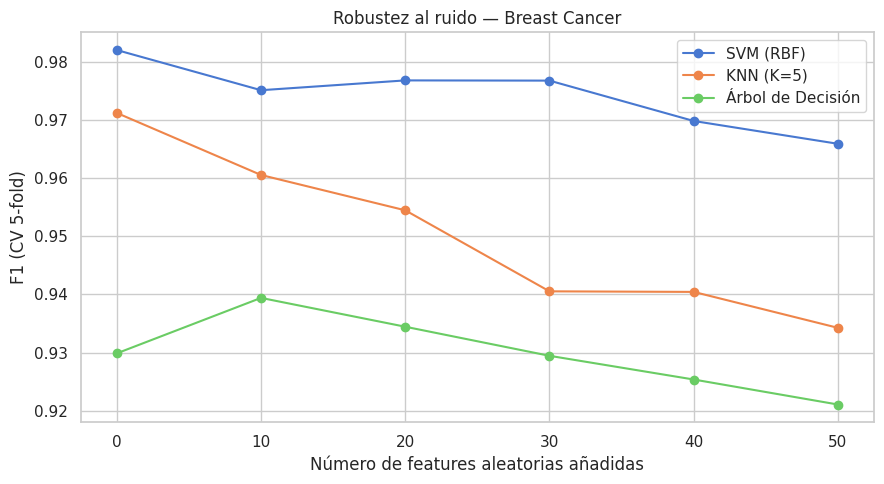

In [46]:
Xc, yc = bc.data, bc.target
cv42 = StratifiedKFold(5, shuffle=True, random_state=42)
modelos_42 = {
    'SVM (RBF)': lambda: make_pipeline(StandardScaler(), SVC(kernel='rbf')),
    'KNN (K=5)': lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'Árbol de Decisión': lambda: DecisionTreeClassifier(random_state=42),
}
n_ruido = [0, 10, 20, 30, 40, 50]
rng = np.random.RandomState(42)
ruido_max = rng.normal(size=(len(Xc), 50))          # 50 columnas de ruido puro; se usan las primeras n en cada experimento

res_42 = {m: [] for m in modelos_42}
for n in n_ruido:
    X_n = np.hstack([Xc, ruido_max[:, :n]]) if n > 0 else Xc
    for nom, fab in modelos_42.items():
        res_42[nom].append(cross_val_score(fab(), X_n, yc, cv=cv42, scoring='f1').mean())
tabla_42 = pd.DataFrame(res_42, index=n_ruido); tabla_42.index.name = 'features de ruido'
display(tabla_42.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
for nom in res_42:
    ax.plot(n_ruido, res_42[nom], 'o-', label=nom)
ax.set_xlabel('Número de features aleatorias añadidas'); ax.set_ylabel('F1 (CV 5-fold)')
ax.set_title('Robustez al ruido — Breast Cancer'); ax.legend(); plt.tight_layout(); plt.show()

In [47]:
# 7. Selección de features (SelectKBest dentro del pipeline, para que se ajuste solo con los datos de entrenamiento de cada fold)
X_50 = np.hstack([Xc, ruido_max])                   # 30 reales + 50 de ruido
fabricas_sel = {
    'SVM (RBF)': lambda: Pipeline([('sc', StandardScaler()), ('sel', SelectKBest(f_classif, k=30)), ('clf', SVC(kernel='rbf'))]),
    'KNN (K=5)': lambda: Pipeline([('sc', StandardScaler()), ('sel', SelectKBest(f_classif, k=30)), ('clf', KNeighborsClassifier(n_neighbors=5))]),
    'Árbol de Decisión': lambda: Pipeline([('sel', SelectKBest(f_classif, k=30)), ('clf', DecisionTreeClassifier(random_state=42))]),
}
filas = []
for nom, fab in fabricas_sel.items():
    con = cross_val_score(fab(), X_50, yc, cv=cv42, scoring='f1').mean()
    filas.append({'Modelo': nom, 'F1 original (0 ruido)': tabla_42.loc[0, nom], 'F1 con 50 ruido': tabla_42.loc[50, nom], 'F1 con 50 ruido + SelectKBest(k=30)': con})
display(pd.DataFrame(filas).set_index('Modelo').round(4))

sel = SelectKBest(f_classif, k=30).fit(StandardScaler().fit_transform(X_50), yc)
n_reales = int((sel.get_support()[:30]).sum())
print('De las 30 features seleccionadas, %d son features reales y %d son ruido.' % (n_reales, 30 - n_reales))

,F1 original (0 ruido),F1 con 50 ruido,F1 con 50 ruido + SelectKBest(k=30)
Modelo,,,
SVM (RBF),0.9820,0.9659,0.9819
KNN (K=5),0.9712,0.9343,0.9674
Árbol de Decisión,0.9299,0.9211,0.9305


De las 30 features seleccionadas, 25 son features reales y 5 son ruido.


#### Respuesta
| F1 (CV) | 0 ruido | 50 ruido | Caída | 50 ruido + SelectKBest(k=30) |
|---|---|---|---|---|
| SVM (RBF) | 0.982 | 0.966 | −1.6 pts | **0.982** |
| KNN (K=5) | 0.971 | 0.934 | **−3.7 pts** | 0.967 |
| Árbol | 0.930 | 0.921 | −0.9 pts | 0.931 |

**¿Qué modelo es más robusto al ruido?** En términos absolutos el **SVM-RBF** (sigue siendo el de mayor F1 incluso con 50 variables de ruido). **KNN es el más sensible**: la distancia euclídea se diluye al añadir dimensiones irrelevantes (con 50 columnas de ruido frente a 30 reales, el ruido domina la distancia): es la "maldición de la dimensionalidad". El árbol cae poco (−0.9 pts) porque en cada división elige la feature más informativa e ignora casi todo el ruido, pero parte de un F1 más bajo y su curva es irregular (incluso sube a 0.939 con 10 columnas de ruido). El SVM, gracias a la regularización y al margen, tolera bastante bien las columnas irrelevantes.

**Técnica de selección de features:** `SelectKBest(f_classif, k=30)` dentro del pipeline (se ajusta solo con el train de cada fold, sin fuga). Recupera el rendimiento: SVM 0.982 (= original), KNN 0.967 (casi el original, 0.971) y Árbol 0.931 (≈ original). De las 30 features seleccionadas, 25 son reales y solo 5 son ruido.